# Sequence Completion (2-gram + 3-gram): DCD grouping → Automated Alignment Search

This notebook adapts the **DCD-Cluster** grouping recipe from Rai, Geva & Yao, *Data-driven Circuit Discovery for Interpretability of Language Models* (arXiv:2605.09129), then runs your existing automated residual-stream alignment search independently within each discovered group.

Pipeline:
1. Generate fixed-length 2-gram-style and 3-gram-style sequence-completion prompts.
2. Construct paper-style corrupted prompts that break the induction cue while preserving token length.
3. Compute a per-example EAP-IG edge-attribution vector using target-vs-foil next-token logit margin.
4. Binarize at 99% absolute attribution mass, reduce to 20 PCA dimensions, and select K with the gap statistic before K-means.
5. Make within-cluster, within-variant donor/base pairs with different target tokens.
6. Run automated alignment search independently per cluster and report selected `(layer, token_position)` nodes, training IIA, validation IIA, no-patch/full-patch baselines, and size-matched random-mask IIA.

**Important:** the paper's sequence-completion construction uses a repeated token sequence with the final repetition truncated. Its counterfactual construction replaces discriminative tokens with fresh tokens not in the clean sequence, across repetitions. The generators below follow that principle with a fixed six-token motif: 2-gram-style motifs `[A B C D E F]` corrupt `E,F`; 3-gram-style motifs `[A B C X E F]` corrupt `X,F`. Prompts are fixed length for position-aligned EAP-IG and activation patching. The exact generator here is a reproducible implementation of the paper's described construction, not a claim that every sampled sequence exactly reproduces the authors' released dataset.

The model is GPT-2 Small, as in the paper's sequence-completion experiments. Install the dependencies, restart the runtime after installing TransformerLens, and run cells top to bottom.

**Layer restriction:** alignment search is restricted to an explicit inclusive layer range (default here **layers 3-8**) via `SEARCH_START_LAYER` / `SEARCH_END_LAYER`; set both to `None` for the middle 60% of layers. This restriction applies to the alignment-search candidate nodes only, not to the model or to the DCD edge-attribution/grouping stage.

**Token restriction (new):** candidate nodes are also restricted in token position, with a data-driven *token window* (first to last position where base/donor tokens differ, final readout position excluded). See section 6. The notebook now also produces the plots and extra experiments in section 7 (results are written to `results/`).


In [1]:
%pip install -q scikit-learn
%pip install "transformer-lens==3.9.0"
%pip install -q git+https://github.com/hannamw/EAP-IG.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 51.8 MB/s  0:00:00
  Created wheel for transformers-stream-generator: filename=transformers_stream_generator-0.0.5-py3-none-any.whl size=12526 sha256=d2a10ef23ea24abe936c6dc49c9858bc3515b9fa2674566e86de2898d571305d
  Stored in directory: /root/.cache/pip/wheels/f6/6e/1a/710143d0e50e827ae5b60a47a6d43d715cf1c6e35881a05530
Successfully built transformers-stream-generator
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [transformer-lens]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import gc
import inspect
import random
import time
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from transformer_lens import HookedTransformer
from eap.graph import Graph
from eap.attribute import attribute

SEED = 32
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


Device: cuda


In [3]:
# GPT-2 Small is also the IOI model used in the DCD paper's model comparison.
model = HookedTransformer.from_pretrained("gpt2", device=device)
model.eval()
model.requires_grad_(False)

# EAP-IG requires these TransformerLens hook/config features for edge attribution.
model.set_use_attn_result(True)
model.set_use_split_qkv_input(True)
model.set_use_hook_mlp_in(True)
# If changing to a GQA model, consult EAP-IG's instructions for ungrouping GQA.

print("Model:", model.cfg.model_name)
print("Layers:", model.cfg.n_layers, "d_model:", model.cfg.d_model)
print("Device:", next(model.parameters()).device)


/tmp/ipykernel_3530/1637305388.py:2: DeprecationWarning: HookedTransformer.from_pretrained is deprecated and will be removed in a future major release. Use TransformerBridge.boot_transformers(...) instead, then call enable_compatibility_mode() for HookedTransformer-equivalent numerics. See docs/source/content/migrating_to_v3.md.
  model = HookedTransformer.from_pretrained("gpt2", device=device)


config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

...

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2 into HookedTransformer
Model: gpt2
Layers: 12 d_model: 768
Device: cuda:0


## 1. Generate the sequence-completion dataset

Each example has a six-token motif and a prompt containing two full motif repetitions followed by the first four motif tokens. The target is the fifth motif token `E`, which follows that truncated prefix. We use two variants:

- **2-gram:** motif `[A, B, C, D, E, F]`; the counterfactual replaces `E` and `F` with fresh tokens throughout each complete repetition.
- **3-gram:** motif `[A, B, C, X, E, F]`; the counterfactual replaces the discriminative interior token `X` and final token `F` throughout each repetition.

For the DCD attribution objective, the clean target-token logit is contrasted against the mean logit of the other five motif tokens. This is a fixed-width label for both variants. The same clean/corrupted pairs are used for attribution-based grouping, following the paper.

In [4]:
# Candidate names are retained only if the token with a leading space is exactly one GPT-2 token.
CANDIDATE_TOKENS = [
    "Mary", "John", "Alice", "Bob", "Michael", "David", "Sarah", "James",
    "Robert", "William", "Linda", "Patricia", "Jennifer", "Susan", "Margaret",
    "Thomas", "Charles", "Daniel", "Matthew", "Anthony", "Mark", "Paul",
    "Steven", "Andrew", "Joshua", "Kevin", "Brian", "George", "Edward",
    "Timothy", "Jason", "Ryan", "Nicholas", "Eric", "Jonathan", "Larry",
    "Rebecca", "Laura", "Karen", "Nancy", "Betty", "Lisa", "Sandra", "Donna",
]

def token_id_with_space(model, word):
    ids = model.to_tokens(" " + word, prepend_bos=False)[0]
    if len(ids) != 1:
        raise ValueError(f"{word!r} is not a single token with a leading space: {ids.tolist()}")
    return int(ids[0].item())

SINGLE_TOKEN_WORDS = []
for word in CANDIDATE_TOKENS:
    try:
        token_id_with_space(model, word)
        SINGLE_TOKEN_WORDS.append(word)
    except ValueError:
        pass

if len(SINGLE_TOKEN_WORDS) < 12:
    raise RuntimeError(f"Need at least 12 single-token words; found {len(SINGLE_TOKEN_WORDS)}")
print(f"Using {len(SINGLE_TOKEN_WORDS)} single-token words:", SINGLE_TOKEN_WORDS)

def sequence_prompt(motif):
    # A fixed text prefix ensures every motif word, including the first, uses its
    # leading-space GPT-2 token. Then repeat twice and end with A B C D; target is E.
    return "Sequence: " + " ".join(motif + motif + motif[:4])

def sequence_corruption(motif, variant, replacements):
    # Apply the same fresh replacement token(s) at every repetition of the motif.
    corrupted_motif = list(motif)
    if variant == "2-gram":
        corrupted_motif[4] = replacements[0]  # E -> CF1
        corrupted_motif[5] = replacements[1]  # F -> CF2
    elif variant == "3-gram":
        corrupted_motif[3] = replacements[0]  # X -> CF1
        corrupted_motif[5] = replacements[1]  # F -> CF2
    else:
        raise ValueError(variant)
    return "Sequence: " + " ".join(corrupted_motif + corrupted_motif + corrupted_motif[:4])

def create_sequence_dataset(model, n_samples=1000, seed=SEED):
    rng = random.Random(seed)
    pool = list(SINGLE_TOKEN_WORDS)
    # Ensure equal counts per variant.
    if n_samples % 2:
        raise ValueError("Use an even n_samples so 2-gram and 3-gram variants are balanced.")
    rows = []
    per_variant = n_samples // 2
    for variant in ("2-gram", "3-gram"):
        seen_motifs = set()
        attempts = 0
        while sum(r["variant"] == variant for r in rows) < per_variant:
            attempts += 1
            if attempts > per_variant * 100:
                raise RuntimeError("Could not generate enough unique motifs; expand CANDIDATE_TOKENS.")
            motif = tuple(rng.sample(pool, 6))
            if motif in seen_motifs:
                continue
            seen_motifs.add(motif)
            clean = sequence_prompt(list(motif))
            replacement_pool = [w for w in pool if w not in motif]
            replacements = rng.sample(replacement_pool, 2)
            corrupted = sequence_corruption(list(motif), variant, replacements)
            # GPT-2 BPE can merge differently across word boundaries; equal word counts
            # do not guarantee equal token counts. Compare without an added BOS token.
            clean_ids = model.to_tokens(clean, prepend_bos=False)[0]
            corrupted_ids = model.to_tokens(corrupted, prepend_bos=False)[0]
            if len(clean_ids) != len(corrupted_ids):
                continue
            # The target is E, the token after the truncated [A B C D] / [A B C X] prefix.
            target_word = motif[4]
            foil_words = [motif[i] for i in range(6) if i != 4]
            rows.append({
                "example_id": len(rows),
                "variant": variant,
                "motif": list(motif),
                "target_word": target_word,
                "target_token_id": token_id_with_space(model, target_word),
                "foil_words": foil_words,
                "foil_token_ids": [token_id_with_space(model, w) for w in foil_words],
                "corrupt_replacements": replacements,
                "clean": clean,
                "corrupted": corrupted,
                "split": None,
            })
    # Stratified 60/20/20 split within each variant to keep both variants represented.
    train_records, val_records, test_records = [], [], []
    split_rng = random.Random(seed + 1)
    for variant in ("2-gram", "3-gram"):
        subset = [r for r in rows if r["variant"] == variant]
        split_rng.shuffle(subset)
        n_tr = int(0.60 * len(subset))
        n_va = int(0.20 * len(subset))
        train_records.extend(subset[:n_tr])
        val_records.extend(subset[n_tr:n_tr+n_va])
        test_records.extend(subset[n_tr+n_va:])
    for r in train_records: r["split"] = "train"
    for r in val_records: r["split"] = "validation"
    for r in test_records: r["split"] = "test"
    return rows, train_records, val_records, test_records

N_EXAMPLES = 1000  # 600 train / 200 validation / 200 held-out test, stratified by variant
records, train_records, val_records, test_records = create_sequence_dataset(model, n_samples=N_EXAMPLES, seed=SEED)

# All prompts should now have the same token length, and each clean/corrupt pair must align.
clean_lengths = {len(model.to_tokens(r["clean"])[0]) for r in records}
corrupt_lengths = {len(model.to_tokens(r["corrupted"])[0]) for r in records}
assert len(clean_lengths) == 1, f"Clean prompts have different token lengths: {sorted(clean_lengths)}"
assert len(corrupt_lengths) == 1, f"Corrupted prompts have different token lengths: {sorted(corrupt_lengths)}"
assert clean_lengths == corrupt_lengths, f"Clean/corrupt lengths differ: {clean_lengths} vs {corrupt_lengths}"

print("Total:", len(records), "| train:", len(train_records), "| validation:", len(val_records), "| held-out test:", len(test_records))
print("Train variants:", Counter(r["variant"] for r in train_records))
example = train_records[0]
print("\nExample variant:", example["variant"])
print("Motif:", example["motif"])
print("Clean:    ", example["clean"])
print("Corrupted:", example["corrupted"])
print("Target:", example["target_word"], "| foils:", example["foil_words"])


Using 44 single-token words: ['Mary', 'John', 'Alice', 'Bob', 'Michael', 'David', 'Sarah', 'James', 'Robert', 'William', 'Linda', 'Patricia', 'Jennifer', 'Susan', 'Margaret', 'Thomas', 'Charles', 'Daniel', 'Matthew', 'Anthony', 'Mark', 'Paul', 'Steven', 'Andrew', 'Joshua', 'Kevin', 'Brian', 'George', 'Edward', 'Timothy', 'Jason', 'Ryan', 'Nicholas', 'Eric', 'Jonathan', 'Larry', 'Rebecca', 'Laura', 'Karen', 'Nancy', 'Betty', 'Lisa', 'Sandra', 'Donna']
Total: 1000 | train: 600 | validation: 200 | held-out test: 200
Train variants: Counter({'2-gram': 300, '3-gram': 300})

Example variant: 2-gram
Motif: ['Eric', 'Edward', 'Donna', 'Matthew', 'George', 'Bob']
Clean:     Sequence: Eric Edward Donna Matthew George Bob Eric Edward Donna Matthew George Bob Eric Edward Donna Matthew
Corrupted: Sequence: Eric Edward Donna Matthew Lisa Patricia Eric Edward Donna Matthew Lisa Patricia Eric Edward Donna Matthew
Target: George | foils: ['Eric', 'Edward', 'Donna', 'Matthew', 'Bob']


## 2. DCD grouping: per-example EAP-IG edge attribution

For each example, we attribute the next-token logit margin

\[
m(x) = \operatorname{logit}(E\mid x) -
\frac{1}{5}\sum_{w\in\{A,B,C,D,F\}}\operatorname{logit}(w\mid x).
\]

The target and foil tokens are taken from that example's motif. The attribution vector covers the model's **edge graph** (not the residual-stream nodes used by the alignment optimizer). The notebook computes one EAP-IG vector per example so that clustering can group examples by their edge-attribution patterns.

In [5]:
def sequence_logit_margin_metric(logits, clean_logits, input_lengths, label):
    """Per-example target logit minus mean foil logit at the final prompt position.

    EAP-IG label tensor shape is [batch, 6]: [target_id, five foil token IDs].
    """
    device = logits.device
    labels = torch.as_tensor(label, device=device, dtype=torch.long)
    if labels.ndim == 1:
        labels = labels.unsqueeze(0)
    lengths = torch.as_tensor(input_lengths, device=device, dtype=torch.long).reshape(-1)
    batch = torch.arange(logits.shape[0], device=device)
    last_pos = lengths - 1
    last_logits = logits[batch, last_pos]
    target_logits = last_logits.gather(1, labels[:, 0:1]).squeeze(1)
    foil_logits = last_logits.gather(1, labels[:, 1:])
    return (target_logits - foil_logits.mean(dim=1)).sum()


class SingleSequenceExampleDataset(Dataset):
    """One clean/corrupted pair and its target + foil token IDs."""
    def __init__(self, row):
        self.row = row
    def __len__(self):
        return 1
    def __getitem__(self, idx):
        r = self.row
        labels = [r["target_token_id"]] + list(r["foil_token_ids"])
        return r["clean"], r["corrupted"], torch.tensor(labels, dtype=torch.long)


def compute_one_eap_ig_vector(row, ig_steps=5):
    """Return this example's real-edge attribution vector as a CPU numpy array."""
    graph = Graph.from_model(model)
    dataloader = DataLoader(SingleSequenceExampleDataset(row), batch_size=1, shuffle=False)
    kwargs = {"method": "EAP-IG-inputs", "ig_steps": ig_steps}
    if "quiet" in inspect.signature(attribute).parameters:
        kwargs["quiet"] = True
    attribute(model, graph, dataloader, sequence_logit_margin_metric, **kwargs)
    scores = graph.scores.detach()
    real_mask = graph.real_edge_mask.to(scores.device).bool()
    vec = scores[real_mask].float().cpu().numpy()
    if vec.ndim != 1 or vec.size == 0:
        raise RuntimeError(f"Expected a non-empty 1D edge-attribution vector, got {vec.shape}")
    return vec


IG_STEPS = 5
# Fit the clustering pipeline on training examples; validation examples are assigned to learned clusters.
cluster_records = train_records + val_records
attr_vectors = []
start = time.time()
for row in tqdm(cluster_records, desc="Per-example EAP-IG"):
    attr_vectors.append(compute_one_eap_ig_vector(row, ig_steps=IG_STEPS))
attr_matrix = np.stack(attr_vectors).astype(np.float32)
print("Attribution matrix shape [examples, real edges]:", attr_matrix.shape)
print(f"Attribution runtime: {(time.time()-start)/60:.1f} minutes")


Per-example EAP-IG:   0%|          | 0/800 [00:00<?, ?it/s]

Attribution matrix shape [examples, real edges]: (800, 32491)
Attribution runtime: 14.7 minutes


## 3. Paper-style preprocessing and clustering

This implements the DCD-Cluster recipe: for each example, sort edges by absolute attribution magnitude and retain the smallest set reaching `gamma = 0.99` of total absolute attribution mass; represent retained edges as a binary vector; reduce to 20 PCA dimensions; choose `K` with the gap statistic and one-standard-error rule; then fit K-means on training examples and assign validation examples to those learned centroids.

The held-out test split is not used for clustering or alignment optimization.

In [6]:
def binarize_attribution_mass(scores, gamma=0.99):
    """Binary vector selecting the smallest top-|attribution| set reaching gamma mass."""
    a = np.abs(np.asarray(scores, dtype=np.float64).reshape(-1))
    out = np.zeros(a.shape[0], dtype=np.uint8)
    total = float(a.sum())
    if total <= 0 or not np.isfinite(total):
        return out
    order = np.argsort(a)[::-1]
    cumulative = np.cumsum(a[order])
    n_keep = int(np.searchsorted(cumulative, gamma * total, side="left") + 1)
    out[order[:n_keep]] = 1
    return out


def kmeans_dispersion(x, k, seed=SEED, n_init=5):
    km = KMeans(n_clusters=int(k), random_state=seed, n_init=n_init)
    labels = km.fit_predict(x)
    w = float(((x - km.cluster_centers_[labels]) ** 2).sum())
    return max(w, 1e-12), km


def choose_k_gap_statistic(x, k_values=range(2, 11), B=20, seed=SEED):
    """Gap statistic with the one-standard-error rule; references uniform in PCA bbox."""
    x = np.asarray(x, dtype=np.float64)
    mins, maxs = x.min(axis=0), x.max(axis=0)
    rng = np.random.default_rng(seed)
    ks = sorted(k for k in k_values if 1 < k < len(x))
    if not ks:
        raise ValueError("Not enough samples for gap-statistic K selection")
    log_w_data = {}
    for k in ks:
        log_w_data[k] = np.log(kmeans_dispersion(x, k, seed=seed, n_init=5)[0])

    log_w_ref = {k: [] for k in ks}
    for b in tqdm(range(B), desc="Gap-statistic references"):
        ref = rng.uniform(mins, maxs, size=x.shape)
        for k in ks:
            w_ref, _ = kmeans_dispersion(ref, k, seed=seed + b + 1, n_init=5)
            log_w_ref[k].append(np.log(w_ref))

    gaps, s_k = {}, {}
    for k in ks:
        vals = np.asarray(log_w_ref[k], dtype=np.float64)
        gaps[k] = float(vals.mean() - log_w_data[k])
        s_k[k] = float(np.sqrt(1.0 + 1.0 / B) * vals.std(ddof=1)) if B > 1 else 0.0

    # Tibshirani et al. one-SE rule: choose smallest k with Gap(k) >= Gap(k+1)-s(k+1).
    chosen = ks[-1]
    for k, k_next in zip(ks[:-1], ks[1:]):
        if gaps[k] >= gaps[k_next] - s_k[k_next]:
            chosen = k
            break
    table = pd.DataFrame({"k": ks, "gap": [gaps[k] for k in ks], "s_k": [s_k[k] for k in ks],
                          "log_W_data": [log_w_data[k] for k in ks]})
    return chosen, table


GAMMA = 0.99
binary_matrix = np.stack([binarize_attribution_mass(v, gamma=GAMMA) for v in attr_matrix])

train_binary = binary_matrix[:len(train_records)]
val_binary = binary_matrix[len(train_records):]
N_PCA = min(20, train_binary.shape[0] - 1, train_binary.shape[1])
if N_PCA < 2:
    raise RuntimeError(f"Too few samples/features for PCA: n_components={N_PCA}")
pca = PCA(n_components=N_PCA, svd_solver="randomized", random_state=42)
train_reduced = pca.fit_transform(train_binary.astype(np.float32))
val_reduced = pca.transform(val_binary.astype(np.float32))
print("PCA shape:", train_reduced.shape, "explained variance:", float(pca.explained_variance_ratio_.sum()))

chosen_k, gap_table = choose_k_gap_statistic(train_reduced, k_values=range(2, 11), B=20, seed=SEED)
print("Gap statistic selected K =", chosen_k)
display(gap_table)

clusterer = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=5)
train_labels = clusterer.fit_predict(train_reduced)
val_labels = clusterer.predict(val_reduced)
for r, lab in zip(train_records, train_labels): r["cluster"] = int(lab)
for r, lab in zip(val_records, val_labels): r["cluster"] = int(lab)

cluster_rows = []
for cluster_id in range(chosen_k):
    tr = [r for r in train_records if r["cluster"] == cluster_id]
    va = [r for r in val_records if r["cluster"] == cluster_id]
    cluster_rows.append({
        "cluster": cluster_id,
        "train_examples": len(tr),
        "validation_examples": len(va),
        "train_2gram": sum(r["variant"] == "2-gram" for r in tr),
        "train_3gram": sum(r["variant"] == "3-gram" for r in tr),
        "validation_2gram": sum(r["variant"] == "2-gram" for r in va),
        "validation_3gram": sum(r["variant"] == "3-gram" for r in va),
        "train_unique_targets": len({r["target_word"] for r in tr}),
        "validation_unique_targets": len({r["target_word"] for r in va}),
    })
cluster_summary = pd.DataFrame(cluster_rows)
display(cluster_summary)


PCA shape: (600, 20) explained variance: 0.10002513974905014


Gap-statistic references:   0%|          | 0/20 [00:00<?, ?it/s]

Gap statistic selected K = 6


,k,gap,s_k,log_W_data
0,2,1.086460,0.008702,12.297518
1,3,1.132075,0.008369,12.195188
2,4,1.155999,0.007895,12.132139
3,5,1.176680,0.008147,12.084006
4,6,1.187994,0.008211,12.049799
5,7,1.189282,0.008464,12.028815
6,8,1.191703,0.009905,12.009623
7,9,1.192281,0.008785,11.994192
8,10,1.187173,0.008544,11.984689


,cluster,train_examples,validation_examples,train_2gram,train_3gram,validation_2gram,validation_3gram,train_unique_targets,validation_unique_targets
0,0,124,42,124,0,42,0,41,30
1,1,118,37,0,118,0,37,33,23
2,2,45,14,0,45,1,13,16,10
3,3,87,23,87,0,23,0,31,16
4,4,89,34,89,0,34,0,37,22
5,5,137,50,0,137,0,50,34,27


## 4. Prepare within-cluster transfer pairs for alignment search

This is distinct from the clean/corrupted pairs used for DCD grouping. Within each cluster and each sequence variant, select a donor/source prompt whose target token differs from the base prompt's target token. The optimizer patches donor residual-stream activations into the base prompt and tests whether the base predicts the donor's target token.

We evaluate only base prompts whose unpatched GPT-2 next-token prediction matches their own sequence-completion target. This makes the IIA task meaningful: the unpatched base should predict its own target, while the patched base should switch to the donor's target. Validation donor/base pairs are built independently from validation examples.

In [7]:
@torch.no_grad()
def predict_next_tokens(model, prompts, batch_size=32):
    """Return argmax next-token IDs for equal-length prompts."""
    if not prompts:
        return []
    toks = [model.to_tokens(p)[0] for p in prompts]
    lens = {int(t.shape[0]) for t in toks}
    if len(lens) != 1:
        raise ValueError(f"Prompts not equal token length: {sorted(lens)}")
    all_ids = torch.stack(toks).to(next(model.parameters()).device)
    preds = []
    for s in range(0, len(prompts), batch_size):
        logits = model(all_ids[s:s+batch_size])
        preds.extend(logits[:, -1, :].argmax(-1).detach().cpu().tolist())
    return preds


def add_clean_correctness_flags(model, rows, batch_size=32):
    preds = predict_next_tokens(model, [r["clean"] for r in rows], batch_size=batch_size)
    for r, pred in zip(rows, preds):
        r["clean_pred_token_id"] = int(pred)
        r["clean_correct"] = (int(pred) == int(r["target_token_id"]))
    return rows

train_records = add_clean_correctness_flags(model, train_records)
val_records = add_clean_correctness_flags(model, val_records)
test_records = add_clean_correctness_flags(model, test_records)
for split_name, split_rows in [("train", train_records), ("validation", val_records), ("test", test_records)]:
    print(f"{split_name} clean next-token accuracy:",
          round(np.mean([r["clean_correct"] for r in split_rows]), 3),
          "| by variant:",
          {v: round(np.mean([r["clean_correct"] for r in split_rows if r["variant"] == v]), 3)
           for v in ("2-gram", "3-gram")})


def build_group_transfer_pairs(rows, rng_seed=SEED):
    """Create (base_prompt, donor_prompt, base_target_id, donor_target_id) pairs."""
    rng = random.Random(rng_seed)
    by_variant = defaultdict(list)
    for r in rows:
        if r.get("clean_correct", False):
            by_variant[(r["cluster"], r["variant"])].append(r)
    pairs = []
    for (cluster, variant), group_rows in by_variant.items():
        for base in group_rows:
            donors = [r for r in group_rows
                      if r["example_id"] != base["example_id"]
                      and r["target_token_id"] != base["target_token_id"]]
            if not donors:
                continue
            donor = rng.choice(donors)
            pairs.append((base["clean"], donor["clean"],
                          int(base["target_token_id"]), int(donor["target_token_id"])))
    return pairs


def target_ids_from_transfer_pairs(pairs):
    return torch.tensor([int(item[3]) for item in pairs], dtype=torch.long)


group_train_pairs = {}
group_val_pairs = {}
for c in range(chosen_k):
    tr_rows = [r for r in train_records if r["cluster"] == c]
    va_rows = [r for r in val_records if r["cluster"] == c]
    group_train_pairs[c] = build_group_transfer_pairs(tr_rows, rng_seed=SEED + 10*c)
    group_val_pairs[c] = build_group_transfer_pairs(va_rows, rng_seed=SEED + 100 + 10*c)

pair_counts = pd.DataFrame([
    {"cluster": c,
     "train_examples": sum(r["cluster"] == c for r in train_records),
     "train_correct_examples": sum(r["cluster"] == c and r["clean_correct"] for r in train_records),
     "train_transfer_pairs": len(group_train_pairs[c]),
     "validation_examples": sum(r["cluster"] == c for r in val_records),
     "validation_correct_examples": sum(r["cluster"] == c and r["clean_correct"] for r in val_records),
     "validation_transfer_pairs": len(group_val_pairs[c])}
    for c in range(chosen_k)
])
display(pair_counts)


train clean next-token accuracy: 0.997 | by variant: {'2-gram': np.float64(0.997), '3-gram': np.float64(0.997)}
validation clean next-token accuracy: 0.995 | by variant: {'2-gram': np.float64(1.0), '3-gram': np.float64(0.99)}
test clean next-token accuracy: 0.995 | by variant: {'2-gram': np.float64(1.0), '3-gram': np.float64(0.99)}


,cluster,train_examples,train_correct_examples,train_transfer_pairs,validation_examples,validation_correct_examples,validation_transfer_pairs
0,0,124,124,124,42,42,42
1,1,118,118,118,37,37,37
2,2,45,45,45,14,14,13
3,3,87,87,87,23,23,23
4,4,89,88,88,34,34,34
5,5,137,136,136,50,49,49


## 5. Automated alignment search

The optimizer below is carried over from your previous notebook: binary-concrete straight-through mask, source-activation caching at `(layer, token_position)` residual-stream nodes, IIA evaluation, random-mask baseline, leave-one-out utilities, and `alignment_find`. The only task-specific change is that target IDs are now the donor's sequence-completion target token.

In [8]:
import time
import random
import torch
import torch.nn.functional as F


# ----------------------------------------------------------------------------
# Mask sampling
# ----------------------------------------------------------------------------
def binary_concrete(logits, K=1.0, hard=True):
    """Return a hard forward mask with sigmoid(K * logits) gradients via STE."""
    if K <= 0:
        raise ValueError("K must be positive")
    mask_soft = torch.sigmoid(K * logits)
    if not hard:
        return mask_soft, mask_soft
    mask_hard = (logits > 0).to(logits.dtype)
    mask_used = mask_hard - mask_soft.detach() + mask_soft
    return mask_used, mask_soft


# ----------------------------------------------------------------------------
# Tokenisation / caching
# ----------------------------------------------------------------------------
def _prompt_tokens(model, prompts, device):
    toks = [model.to_tokens(p)[0] for p in prompts]
    L = toks[0].shape[0]
    if any(t.shape[0] != L for t in toks):
        raise ValueError("All prompts must tokenize to the same length")
    return torch.stack(toks).to(device)


def _prepare(model, data, nodes, cfa_tok_id, cache_bs=32):
    """
    Tokenize once and cache SOURCE activations once (on CPU) at only the requested nodes.

    cfa_tok_id : source target-token IDs, shape [N]; one target token per pair.
    Nodes must lie inside the prompt (pos < L) because source activations come from the
    source prompt alone.
    """
    device = next(model.parameters()).device
    gold = torch.as_tensor(cfa_tok_id, dtype=torch.long)
    if gold.ndim == 1:
        gold = gold[:, None]
    N, K = gold.shape
    if N != len(data) or N == 0:
        raise ValueError("data and cfa_tok_id must have equal, nonzero lengths")

    base_ptok = _prompt_tokens(model, [item[0] for item in data], device)
    src_tok = _prompt_tokens(model, [item[1] for item in data], device)
    L = base_ptok.shape[1]
    if src_tok.shape[1] != L:
        raise ValueError(f"Base ({L}) and source ({src_tok.shape[1]}) prompts differ in token length")

    gold = gold.to(device)
    base_tok = torch.cat([base_ptok, gold[:, : K - 1]], dim=1)  # prompt + teacher-forced answer prefix

    n_layers = model.cfg.n_layers
    layer_entries = {}
    for i, (layer, pos) in enumerate(nodes):
        if not 0 <= pos < L:
            raise ValueError(f"Token position {pos} outside the prompt (length {L})")
        if not 0 <= layer < n_layers:
            raise ValueError(f"Layer {layer} outside model (n_layers={n_layers})")
        layer_entries.setdefault(layer, []).append((i, pos))

    d = model.cfg.d_model
    src_cache = None
    with torch.no_grad():
        for start in range(0, N, cache_bs):
            sl = slice(start, start + cache_bs)
            grabbed = {}

            def make_hook(layer):
                def hook(act, hook=None):
                    grabbed[layer] = torch.stack(
                        [act[:, p, :] for _, p in layer_entries[layer]], dim=0
                    ).detach().cpu()
                    return act
                return hook

            model.run_with_hooks(
                src_tok[sl],
                fwd_hooks=[(f"blocks.{l}.hook_resid_post", make_hook(l)) for l in layer_entries],
                return_type=None,
            )
            if src_cache is None:
                src_cache = torch.zeros(len(nodes), N, d, dtype=next(iter(grabbed.values())).dtype)
            for layer, entries in layer_entries.items():
                for k, (i, _) in enumerate(entries):
                    src_cache[i, sl] = grabbed[layer][k]

    return {"base_tok": base_tok, "src_cache": src_cache, "layer_entries": layer_entries,
            "gold": gold, "L": L, "K": K, "N": N}


def _forward_with_mask(model, prep, idx, m):
    """Interchange-intervened forward on base examples `idx`; m is a [n_nodes] 0/1 (or relaxed) tensor.
    Returns logits at the K answer positions: [B, K, vocab]."""
    base_tok, layer_entries = prep["base_tok"], prep["layer_entries"]
    device = base_tok.device
    src_b = prep["src_cache"][:, idx].to(device)  # [n_nodes, B, d]

    def make_hook(layer):
        entries = layer_entries[layer]

        def hook(act, hook=None):
            act = act.clone()
            for i, p in entries:
                cur = act[:, p, :]
                act[:, p, :] = cur + m[i].to(act.dtype) * (src_b[i].to(act.dtype) - cur)
            return act
        return hook

    logits = model.run_with_hooks(
        base_tok[idx.to(device)],
        fwd_hooks=[(f"blocks.{l}.hook_resid_post", make_hook(l)) for l in layer_entries],
        return_type="logits",
    )
    L, K = prep["L"], prep["K"]
    return logits[:, L - 1: L - 1 + K, :]


# ----------------------------------------------------------------------------
# Evaluation helpers
# ----------------------------------------------------------------------------
@torch.no_grad()
def evaluate_iia(model, data, nodes, gold_ids, mask_hard, batch_size=16, prepared=None, flip=None):
    """
    Exact IIA with a fixed hard mask (no noise).
    IIA = fraction of base prompts where the intervened next token matches the source target token.
    `flip` optionally separates carry-changing from carry-preserving examples.
    """
    model.eval()
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    device = prep["base_tok"].device
    m = torch.as_tensor(mask_hard).to(device).float()
    N, K = prep["N"], prep["K"]
    hit = torch.zeros(N, K, dtype=torch.bool)
    for s in range(0, N, batch_size):
        idx = torch.arange(s, min(s + batch_size, N))
        pred = _forward_with_mask(model, prep, idx, m).argmax(-1).cpu()
        hit[idx] = pred == prep["gold"][idx.to(device)].cpu()
    ok = hit.all(-1)
    out = {"iia": ok.float().mean().item(), "per_digit": hit.float().mean(0).tolist()}
    if flip is not None:
        f = torch.as_tensor(flip, dtype=torch.bool)
        out["iia_flip"] = ok[f].float().mean().item() if f.any() else float("nan")
        out["iia_same"] = ok[~f].float().mean().item() if (~f).any() else float("nan")
    return out


def random_mask_baseline(model, data, nodes, gold_ids, k, n_trials=10, prepared=None, flip=None):
    """Mean IIA of random masks with k active nodes -- the reference the found mask must beat."""
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    runs = []
    for _ in range(n_trials):
        m = torch.zeros(len(nodes))
        m[torch.randperm(len(nodes))[:k]] = 1
        runs.append(evaluate_iia(model, data, nodes, gold_ids, m, prepared=prep, flip=flip))
    return {key: float(sum(r[key] for r in runs) / len(runs)) for key in runs[0] if key != "per_digit"}


def leave_one_out(model, data, nodes, gold_ids, mask_hard, prepared=None, flip=None):
    """IIA after removing each selected node in turn. A big drop means the node is necessary."""
    prep = prepared if prepared is not None else _prepare(model, data, nodes, gold_ids)
    mask_hard = torch.as_tensor(mask_hard).clone()
    rows = []
    for i in torch.nonzero(mask_hard).flatten().tolist():
        m = mask_hard.clone()
        m[i] = 0
        r = evaluate_iia(model, data, nodes, gold_ids, m, prepared=prep, flip=flip)
        rows.append((nodes[i], r.get("iia_flip", r["iia"])))
    return rows


def summarize_nodes(selected_nodes):
    """Group selected (layer, pos) cells by token position and show layer ranges."""
    by_pos = {}
    for layer, pos in selected_nodes:
        by_pos.setdefault(pos, []).append(layer)
    lines = []
    for pos in sorted(by_pos):
        layers = sorted(by_pos[pos])
        runs, start = [], layers[0]
        for a, b in zip(layers, layers[1:] + [None]):
            if b is None or b != a + 1:
                runs.append(f"{start}" if start == a else f"{start}-{a}")
                start = b
        lines.append(f"  pos {pos}: layers {', '.join(runs)}")
    return "\n".join(lines) if lines else "  (no nodes selected)"


# ----------------------------------------------------------------------------
# The alignment search
# ----------------------------------------------------------------------------
def alignment_find(
    data, model, nodes, cfa_tok_id,
    alpha_init=None, init_logit=-0.5,
    lambda_=0.1, K=1.0, lr=5e-2, n_epochs=100,
    micro_batch=8,
    penalty_kind="sigmoid", hard=True, verbose=True,
    prepared=None, seed=None, log_every=25,
):
    """
    data        : list of (base_prompt, source_prompt, base_label, source_label), equal token length
    nodes       : list of unique (layer, token_pos) cells (resid_post, pos inside the prompt)
    cfa_tok_id  : source target-token IDs, [N]
    alpha_init  : optional tensor [n_nodes] of initial selection logits

    Each epoch uses the entire dataset. Source activations are cached once on CPU; gradients accumulate
    over micro-batches, then flow through the straight-through mask estimator.
    """
    if not nodes or len(set(nodes)) != len(nodes):
        raise ValueError("nodes must be non-empty and unique")
    if penalty_kind not in ("l1", "sigmoid"):
        raise ValueError("penalty_kind must be 'l1' or 'sigmoid'")
    if seed is not None:
        torch.manual_seed(seed)

    model.eval()
    model.requires_grad_(False)
    device = next(model.parameters()).device
    t0 = time.time()

    prep = prepared if prepared is not None else _prepare(model, data, nodes, cfa_tok_id)
    gold, N, num_targets = prep["gold"], prep["N"], prep["K"]
    if verbose:
        print(f"[prep] cached sources for {len(nodes)} nodes x {N} pairs in {time.time() - t0:.1f}s")

    if alpha_init is None:
        alpha = torch.full((len(nodes),), float(init_logit), device=device)
    else:
        alpha = alpha_init.detach().to(device).float().clone()
    alpha = torch.nn.Parameter(alpha)
    opt = torch.optim.Adam([alpha], lr=lr)

    history = []
    for epoch in range(n_epochs):
        opt.zero_grad(set_to_none=True)
        idx_all = torch.arange(N)

        mask_used, mask_soft = binary_concrete(alpha, K=K, hard=hard)
        m_leaf = mask_used.detach().clone().requires_grad_(True)  # cut the graph; grads accumulate here

        ce_total = 0.0
        for s in range(0, len(idx_all), micro_batch):
            idx = idx_all[s: s + micro_batch]
            with torch.enable_grad():
                logits = _forward_with_mask(model, prep, idx, m_leaf)  # [B, 1, V]
                loss = F.cross_entropy(
                    logits.reshape(-1, logits.shape[-1]).float(),
                    gold[idx.to(device)].reshape(-1),
                    reduction="sum",
                ) / (len(idx_all) * num_targets)
                loss.backward()  # frees this micro-batch graph immediately
            ce_total += loss.item()

        g = m_leaf.grad if m_leaf.grad is not None else torch.zeros_like(m_leaf)
        probs = torch.sigmoid(K * alpha) if penalty_kind == "sigmoid" else mask_soft
        #penalty = lambda_ * probs.mean()
        probs = torch.sigmoid(K * alpha)
        penalty = lambda_ * probs.sum()
        # One backward handles the mask objective and sparsity penalty together.
        ((mask_used * g).sum() + penalty).backward()
        opt.step()

        history.append({"epoch": epoch + 1, "ce": float(ce_total), "penalty": float(penalty.item()),
                        "n_selected": int((alpha > 0).sum().item())})

        if verbose and (epoch % log_every == 0 or epoch == n_epochs - 1):
            with torch.no_grad():
                sel = int((alpha > 0).sum().item())
            print(f"[epoch {epoch + 1:4d}/{n_epochs}] ce={ce_total:.4f} pen={penalty.item():.4f} "
                  f"selected={sel}/{len(nodes)}  ({time.time() - t0:.0f}s)")
            print(f"alpha: min={alpha.min().item():.4f}, max={alpha.max().item():.4f}, "
                    f"mean={alpha.mean().item():.4f}")
            print(f"grad_norm={alpha.grad.norm().item():.6f}")

    with torch.no_grad():
        hard_mask = (alpha > 0).to(torch.int64).cpu()
    return {
        "alpha": alpha.detach().cpu(),
        "mask_hard": hard_mask,
        "selected_nodes": [nodes[i] for i in range(len(nodes)) if hard_mask[i].item() == 1],
        "history": history,
        "seconds": time.time() - t0,
    }

## 6. Run alignment search independently for each DCD group

### Candidate-node restrictions (layers **and** tokens)

An alignment-search node is a residual-stream cell `(layer, token_position)` (`hook_resid_post`). Both axes of the grid are restricted:

**Layers.** Inclusive range `SEARCH_START_LAYER … SEARCH_END_LAYER` (default here: **3 … 8**). Early layers mostly re-encode the input token identity, and the last layers are the readout, so patching there makes IIA trivially high.

**Tokens (new).** The token restriction mirrors the layer restriction and the causal argument used in the carry-ones notebook (positions that cannot yet contain the varied information are never expected to be selected). It is computed from the data rather than hard-coded, by `build_token_window(...)`:

1. **Lower bound - causality.** The residual stream at position *p* depends only on tokens `<= p`. Positions before the first token at which base and donor prompts differ carry identical activations in both prompts, so patching them is a no-op. They are dropped.
2. **Upper bound - no "later tokens" / no readout.** The final prompt position is excluded, exactly as the carry-ones notebook excluded `final_prompt_pos`. At the final position the model's next-token readout is formed, so patching it just overwrites the answer with the donor's answer: the high IIA says nothing about *where the information is represented upstream*. For sequence completion: every motif token differs between donor and base, so the span runs from the first motif token to the position before the final one. The previous (unrestricted) run selected the final position (19) at layers 7-9 in every cluster, i.e. a readout shortcut. `up_to:15` removes the query repetition (answer must then be read from the two earlier repetitions) and `up_to:9` keeps only the first repetition, where the target E sits at position 8.
3. **Default policy `diff_span`** = the contiguous span from the first to the last position where base/donor tokens differ in at least `MIN_DIFF_FRAC` of the training pairs, with the final position removed. Other policies (`all`, `no_final`, `diff_tokens`, `up_to:K`) are used in the *window-sweep experiment* below to show what each restriction changes.

The restriction applies to the alignment-search candidate nodes only, not to the model, to DCD edge attribution, or to the clustering stage. The held-out `test_records` split is not used for clustering, optimisation or validation reporting (it is used once, in the confirmatory test cell).


In [9]:
import json
from pathlib import Path
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

OUT_DIR = Path("results")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ----------------------------------------------------------------------------
# Search settings
# ----------------------------------------------------------------------------
# --- layer restriction (inclusive). None -> middle SEARCH_LAYERS_FRACTION of the model.
SEARCH_LAYERS_FRACTION = 0.60
SEARCH_START_LAYER = 3
SEARCH_END_LAYER = 8

# --- token restriction
TOKEN_POLICY = "diff_span"     # all | no_final | diff_span | diff_tokens | up_to:K
MIN_DIFF_FRAC = 0.5            # a position "differs" if >= this fraction of training pairs differ there
ALLOW_FINAL_POSITION = False   # keep False: the final prompt position is the readout
SEARCH_MIN_POS = None          # optional manual inclusive bounds applied on top of the policy
SEARCH_MAX_POS = None

# --- optimiser (unchanged from the carry-ones notebook)
SEARCH_EPOCHS = 350
SEARCH_LAMBDA = 0.1
SEARCH_K = 4.0
SEARCH_LR = 5e-3
SEARCH_MICRO_BATCH = 8
MIN_TRAIN_PAIRS = 8
MIN_VAL_PAIRS = 4
RANDOM_BASELINE_TRIALS = 20

prompt_length = model.to_tokens(train_records[0]["clean"]).shape[1]
n_layers = int(model.cfg.n_layers)

default_start = int(np.floor(((1.0 - SEARCH_LAYERS_FRACTION) / 2.0) * n_layers))
default_end_exclusive = int(np.ceil(((1.0 + SEARCH_LAYERS_FRACTION) / 2.0) * n_layers))
start_layer = default_start if SEARCH_START_LAYER is None else int(SEARCH_START_LAYER)
end_layer = (default_end_exclusive - 1) if SEARCH_END_LAYER is None else int(SEARCH_END_LAYER)
if not (0 <= start_layer <= end_layer < n_layers):
    raise ValueError(f"Invalid inclusive layer range [{start_layer}, {end_layer}] for {n_layers} layers.")
search_layers = list(range(start_layer, end_layer + 1))

# ----------------------------------------------------------------------------
# Checkpoint the expensive stage so a restart does not repeat ~15 min of EAP-IG
# ----------------------------------------------------------------------------
try:
    np.save(OUT_DIR / "attr_matrix.npy", attr_matrix)
    pd.DataFrame([{"example_id": r["example_id"], "split": r["split"], "variant": r["variant"],
                   "cluster": r["cluster"]} for r in train_records + val_records]
                 ).to_csv(OUT_DIR / "cluster_assignments.csv", index=False)
    print("Saved attr_matrix.npy and cluster_assignments.csv to", OUT_DIR)
except Exception as e:
    print("Checkpoint skipped:", e)

# ----------------------------------------------------------------------------
# Token window
# ----------------------------------------------------------------------------
def position_difference_profile(pairs):
    """Fraction of (base, donor) pairs whose token differs at each position -> array [L]."""
    base = _prompt_tokens(model, [p[0] for p in pairs], "cpu")
    src = _prompt_tokens(model, [p[1] for p in pairs], "cpu")
    return (base != src).float().mean(0).numpy()


def build_token_window(profile, policy="diff_span", min_diff_frac=0.5, allow_final=False,
                       min_pos=None, max_pos=None):
    """Return the sorted list of token positions eligible for alignment-search nodes. BOS (0) is never eligible."""
    L = len(profile)
    final = L - 1
    usable_max = final if allow_final else final - 1
    differing = [p for p in range(1, L) if profile[p] >= min_diff_frac and p <= usable_max]
    if policy == "all":
        pos = list(range(1, L))
    elif policy == "no_final":
        pos = list(range(1, final))
    elif policy in ("diff_span", "diff_tokens") or policy.startswith("up_to:"):
        if not differing:
            raise ValueError("No position differs between base and donor prompts in enough pairs.")
        if policy == "diff_span":
            pos = list(range(min(differing), max(differing) + 1))
        elif policy == "diff_tokens":
            pos = differing
        else:
            k = min(int(policy.split(":")[1]), usable_max)
            d = [p for p in differing if p <= k]
            if not d:
                raise ValueError(f"No differing position <= {k}.")
            pos = list(range(min(d), k + 1))
    else:
        raise ValueError(f"Unknown token policy {policy!r}")
    if min_pos is not None:
        pos = [p for p in pos if p >= min_pos]
    if max_pos is not None:
        pos = [p for p in pos if p <= max_pos]
    if not pos:
        raise ValueError("Token window is empty after applying bounds.")
    return sorted(pos)


def make_nodes(layers, positions):
    return [(l, p) for l in layers for p in positions]


all_train_pairs = [p for c in range(chosen_k) for p in group_train_pairs[c]]
diff_profile = position_difference_profile(all_train_pairs)
example_prompt = all_train_pairs[0][0]
example_tokens = model.to_str_tokens(example_prompt)
final_position = prompt_length - 1

window_positions = build_token_window(diff_profile, TOKEN_POLICY, MIN_DIFF_FRAC,
                                      ALLOW_FINAL_POSITION, SEARCH_MIN_POS, SEARCH_MAX_POS)
nodes = make_nodes(search_layers, window_positions)

print(f"Search layers (inclusive): {search_layers}")
print(f"Token policy {TOKEN_POLICY!r} -> positions {window_positions[0]}..{window_positions[-1]} "
      f"({len(window_positions)} positions); final prompt position {final_position} "
      f"{'INCLUDED' if final_position in window_positions else 'excluded'}")
print(f"Candidate residual-stream nodes: {len(nodes)} (was {len(search_layers) * (prompt_length - 1)} with all positions)")
print("\nPosition  token (example prompt)   frac. of pairs where base/donor token differs   in window")
for p in range(prompt_length):
    print(f"  {p:2d}      {example_tokens[p]!r:<22} {diff_profile[p]:.2f}                                          "
          f"{'yes' if p in window_positions else 'no'}")


def nodes_with_token_labels(selected_nodes, prompt):
    toks = model.to_str_tokens(prompt)
    return [{"layer": int(layer), "position": int(pos),
             "token": toks[pos] if pos < len(toks) else "<out-of-range>"}
            for layer, pos in selected_nodes]


# ----------------------------------------------------------------------------
# Generic per-cluster search (same optimiser as before; adds history, LOO, random-baseline samples)
# ----------------------------------------------------------------------------
def random_baseline_samples(val_pairs, val_gold, search_nodes, k, n_trials, prep):
    out = []
    for _ in range(n_trials):
        m = torch.zeros(len(search_nodes))
        m[torch.randperm(len(search_nodes))[:k]] = 1
        out.append(evaluate_iia(model, val_pairs, search_nodes, val_gold, m, prepared=prep)["iia"])
    return out


def run_group_search(cluster_id, train_pairs, val_pairs, search_nodes, epochs=None, seed_offset=0,
                     lambda_=None, n_random=None, verbose=True, do_loo=True):
    epochs = SEARCH_EPOCHS if epochs is None else epochs
    lambda_ = SEARCH_LAMBDA if lambda_ is None else lambda_
    n_random = RANDOM_BASELINE_TRIALS if n_random is None else n_random
    if verbose:
        print("\n" + "=" * 88)
        print(f"DCD cluster {cluster_id}: train pairs={len(train_pairs)}, validation pairs={len(val_pairs)}, "
              f"candidate nodes={len(search_nodes)}")
    if len(train_pairs) < MIN_TRAIN_PAIRS or len(val_pairs) < MIN_VAL_PAIRS:
        print(f"cluster {cluster_id}: SKIPPED (insufficient within-cluster transfer pairs; a data-support issue, not IIA=0).")
        return {"cluster": cluster_id, "status": "skipped", "train_pairs": len(train_pairs),
                "val_pairs": len(val_pairs), "selected_nodes": [], "val_iia": np.nan}

    train_gold = target_ids_from_transfer_pairs(train_pairs)
    val_gold = target_ids_from_transfer_pairs(val_pairs)
    train_prep = _prepare(model, train_pairs, search_nodes, train_gold)
    val_prep = _prepare(model, val_pairs, search_nodes, val_gold)
    val_no_patch = evaluate_iia(model, val_pairs, search_nodes, val_gold,
                                torch.zeros(len(search_nodes)), prepared=val_prep)
    val_full_patch = evaluate_iia(model, val_pairs, search_nodes, val_gold,
                                  torch.ones(len(search_nodes)), prepared=val_prep)

    result = alignment_find(
        data=train_pairs, model=model, nodes=search_nodes, cfa_tok_id=train_gold,
        lambda_=lambda_, K=SEARCH_K, lr=SEARCH_LR, n_epochs=epochs,
        micro_batch=SEARCH_MICRO_BATCH, penalty_kind="sigmoid", hard=True,
        verbose=verbose, prepared=train_prep, seed=SEED + cluster_id + 1000 * seed_offset,
        log_every=max(1, epochs // 7),
    )
    selected, mask = result["selected_nodes"], result["mask_hard"]
    train_iia = evaluate_iia(model, train_pairs, search_nodes, train_gold, mask, prepared=train_prep)["iia"]
    val_iia = evaluate_iia(model, val_pairs, search_nodes, val_gold, mask, prepared=val_prep)["iia"]
    rand = (random_baseline_samples(val_pairs, val_gold, search_nodes, len(selected), n_random, val_prep)
            if len(selected) > 0 else [])
    loo = None
    if do_loo and 0 < len(selected) <= 30:
        loo = leave_one_out(model, val_pairs, search_nodes, val_gold, mask, prepared=val_prep)
    labels = nodes_with_token_labels(selected, val_pairs[0][0])
    n_final = sum(1 for _, p in selected if p == final_position)

    if verbose:
        print(f"\nCluster {cluster_id} RESULTS")
        print(f"  selected nodes: {len(selected)} / {len(search_nodes)}   (at the final position: {n_final})")
        print(f"  train IIA: {train_iia:.3f} | validation IIA: {val_iia:.3f} | val no-patch: {val_no_patch['iia']:.3f} "
              f"| val all-candidate-nodes: {val_full_patch['iia']:.3f} | val random same-size: "
              f"{(np.mean(rand) if rand else float('nan')):.3f}")
        print("  selected (layer, pos) nodes:", selected)
        for e in labels:
            print("   ", e)
        if loo:
            print("  leave-one-out validation IIA (lower = node more necessary):")
            for node, v in sorted(loo, key=lambda x: x[1]):
                print(f"   without {node}: {v:.3f}")

    return {
        "cluster": cluster_id, "status": "ok", "train_pairs": len(train_pairs), "val_pairs": len(val_pairs),
        "nodes": search_nodes, "selected_nodes": selected, "selected_node_labels": labels,
        "n_selected": len(selected), "n_final_position": n_final,
        "train_iia": float(train_iia), "val_iia": float(val_iia),
        "val_no_patch_iia": float(val_no_patch["iia"]), "val_full_patch_iia": float(val_full_patch["iia"]),
        "val_random_mask_iia": float(np.mean(rand)) if rand else np.nan,
        "val_random_mask_iia_std": float(np.std(rand)) if rand else np.nan,
        "loo": loo, "mask_hard": mask, "alpha": result["alpha"], "history": result["history"],
        "seconds": result["seconds"],
    }


Saved attr_matrix.npy and cluster_assignments.csv to results
Search layers (inclusive): [3, 4, 5, 6, 7, 8]
Token policy 'diff_span' -> positions 4..18 (15 positions); final prompt position 19 excluded
Candidate residual-stream nodes: 90 (was 114 with all positions)

Position  token (example prompt)   frac. of pairs where base/donor token differs   in window
   0      '<|endoftext|>'        0.00                                          no
   1      'Sequ'                 0.00                                          no
   2      'ence'                 0.00                                          no
   3      ':'                    0.00                                          no
   4      ' Eric'                0.98                                          yes
   5      ' Edward'              0.98                                          yes
   6      ' Donna'               0.98                                          yes
   7      ' Matthew'             0.96                          

In [10]:
# One independent optimiser run per DCD cluster, with the restricted layer x token grid.
search_results = {}
for c in range(chosen_k):
    search_results[c] = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes)
ok_clusters = [c for c in range(chosen_k) if search_results[c]["status"] == "ok"]

group_results_table = pd.DataFrame([
    {k: res.get(k) for k in ["cluster", "status", "train_pairs", "val_pairs", "n_selected", "n_final_position",
                             "train_iia", "val_iia", "val_no_patch_iia", "val_full_patch_iia",
                             "val_random_mask_iia", "seconds"]}
    for res in search_results.values()
])
display(group_results_table)

selected_table = pd.DataFrame([
    {"cluster": c, "n_nodes": r["n_selected"], "val_iia": round(r["val_iia"], 3),
     "nodes (layer, pos:token)": ", ".join(f"({e['layer']}, {e['position']}:{e['token'].strip()})"
                                           for e in r["selected_node_labels"])}
    for c, r in search_results.items() if r["status"] == "ok"
])
display(selected_table)



DCD cluster 0: train pairs=124, validation pairs=42, candidate nodes=90
[prep] cached sources for 90 nodes x 124 pairs in 0.0s
[epoch    1/350] ce=10.2817 pen=1.0728 selected=0/90  (3s)
alpha: min=-0.5050, max=-0.4950, mean=-0.5022
grad_norm=4.693261
[epoch   51/350] ce=10.2817 pen=1.0484 selected=0/90  (122s)
alpha: min=-0.7297, max=-0.2249, mean=-0.5895
grad_norm=8.962132
[epoch  101/350] ce=3.8851 pen=1.4790 selected=19/90  (241s)
alpha: min=-0.9456, max=0.0488, mean=-0.6310
grad_norm=0.849799
[epoch  151/350] ce=3.8081 pen=1.2774 selected=12/90  (360s)
alpha: min=-1.2332, max=0.2378, mean=-0.6906
grad_norm=0.559245
[epoch  201/350] ce=3.6928 pen=1.2458 selected=11/90  (479s)
alpha: min=-1.3707, max=0.4613, mean=-0.7190
grad_norm=0.501973
[epoch  251/350] ce=4.2395 pen=1.2869 selected=11/90  (598s)
alpha: min=-1.4719, max=0.5956, mean=-0.7377
grad_norm=1.422843
[epoch  301/350] ce=3.8527 pen=1.2493 selected=11/90  (717s)
alpha: min=-1.5589, max=0.6806, mean=-0.7693
grad_norm=1.2262

,cluster,status,train_pairs,val_pairs,n_selected,n_final_position,train_iia,val_iia,val_no_patch_iia,val_full_patch_iia,val_random_mask_iia,seconds
0,0,ok,124,42,8,0,0.717742,0.595238,0.0,0.190476,0.035714,833.037131
1,1,ok,118,37,7,0,0.305085,0.378378,0.0,0.189189,0.071622,789.310672
2,2,ok,45,13,8,0,0.044444,0.000000,0.0,0.000000,0.019231,303.528165
3,3,ok,87,23,11,0,0.091954,0.086957,0.0,0.043478,0.073913,583.249902
4,4,ok,88,34,6,0,0.602273,0.705882,0.0,0.205882,0.057353,588.615446
5,5,ok,136,49,7,0,0.132353,0.102041,0.0,0.224490,0.065306,908.708117


,cluster,n_nodes,val_iia,"nodes (layer, pos:token)"
0,0,8,0.595,"(3, 8:Thomas), (3, 14:Thomas), (4, 9:Robert), ..."
1,1,7,0.378,"(3, 8:William), (4, 9:Charles), (4, 14:William..."
2,2,8,0.000,"(3, 8:Nicholas), (4, 8:Nicholas), (4, 9:Rebecc..."
3,3,11,0.087,"(3, 8:Brian), (3, 14:Brian), (4, 7:Larry), (4,..."
4,4,6,0.706,"(3, 8:Jason), (3, 13:Thomas), (3, 14:Jason), (..."
5,5,7,0.102,"(3, 8:John), (4, 8:John), (4, 15:Edward), (5, ..."


## 7. Plots and additional experiments

Every figure is written to `results/figures/*.png`. Categorical colours follow a fixed order (never cycled, one slot per DCD cluster); magnitudes use a single-hue sequential ramp.

| Cell | Question |
|---|---|
| 7.1 | How do the groups look (composition, gap statistic, PCA), and how well does each learned mask do (IIA vs baselines, optimisation curves, selected-node maps, leave-one-out)? |
| 7.2 | **Single-node / single-position IIA maps** - where in the *full* layer x token grid does patching alone transfer the donor answer? Positions outside the token window are shown so you can see what the restriction removes. |
| 7.3 | **Cross-cluster mask transfer** - does cluster *i*'s mask transfer the answer on cluster *j*'s validation pairs? (Analogue of the paper's cross-variant faithfulness matrices.) |
| 7.4 | **Token-window sweep** - re-run the search under `all`, `no_final`, `diff_span`, ... to measure how much of the high IIA comes from late tokens / the readout position. |
| 7.5 | *(optional)* seed stability and sparsity (lambda) sweep. |
| 7.6 | Confirmatory evaluation on the untouched test split. |
| 7.7 | Save everything to `results/`. |


In [11]:
# ---------------- plotting helpers ----------------
# Categorical slots in fixed order (one per DCD cluster); clusters beyond 8 fall back to neutral grey.
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GREY = "#8a8a85"
def cluster_color(c): return CAT[c] if c < len(CAT) else GREY
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "font.size": 10})
SEQ = "Blues"   # one-hue sequential ramp for magnitudes (IIA in [0, 1])

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()

def pos_tick_labels(positions):
    return [f"{p}\n{example_tokens[p].strip()[:7]}" for p in positions]

variants = sorted({r["variant"] for r in train_records})


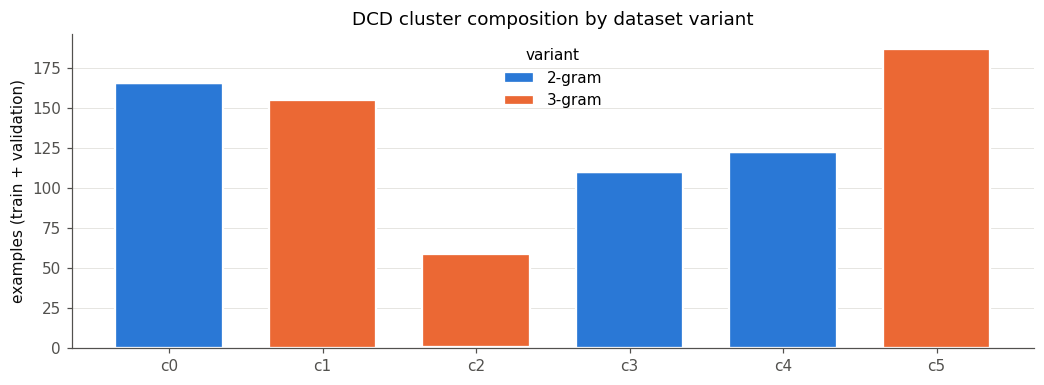

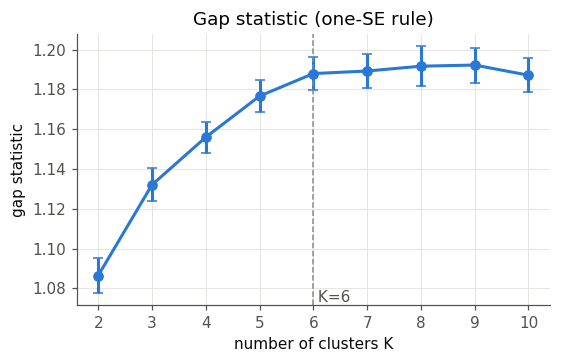

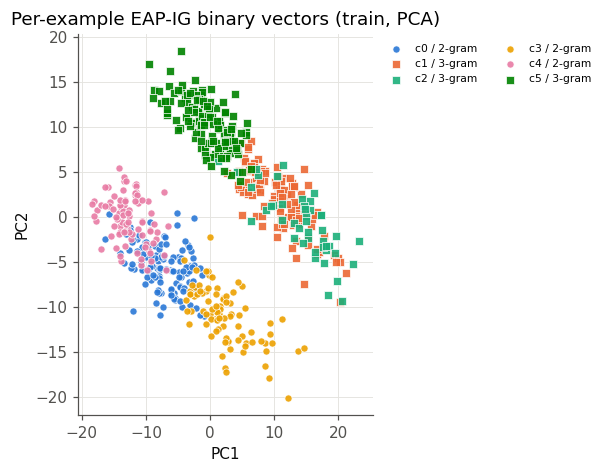

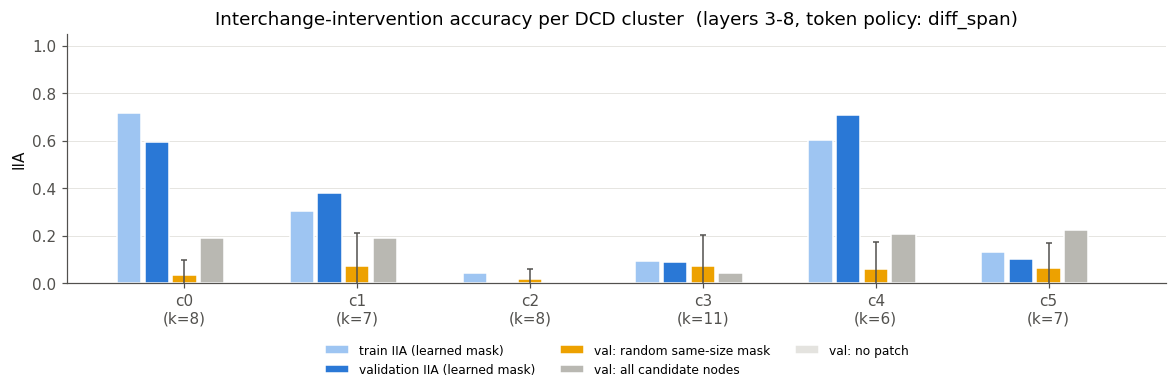

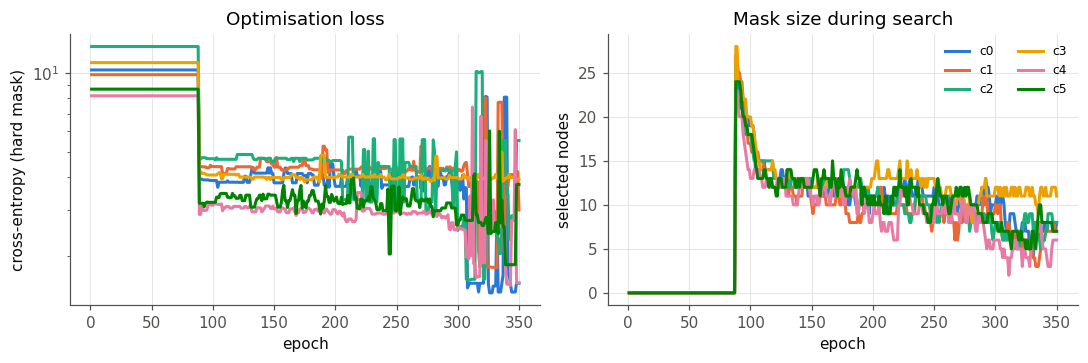

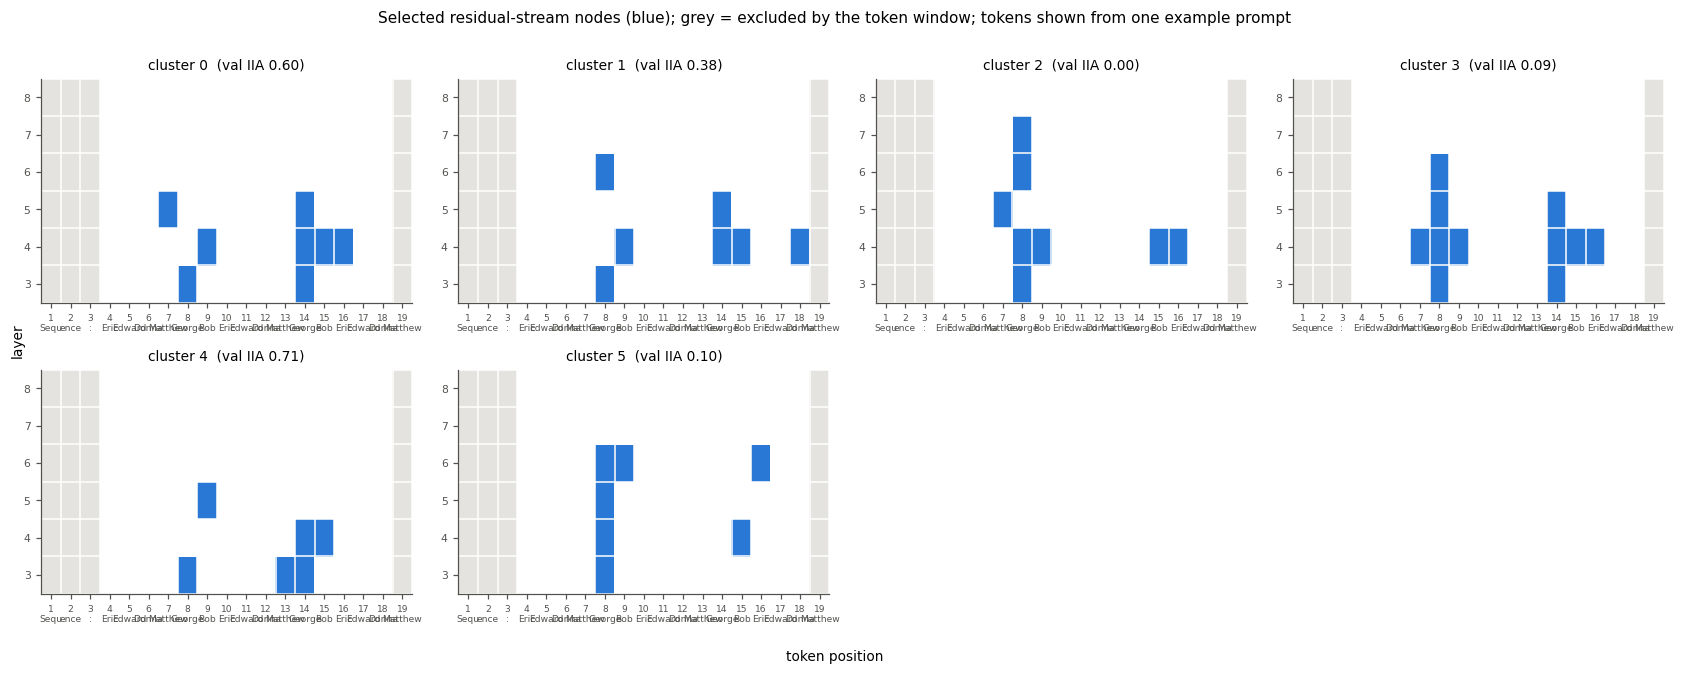

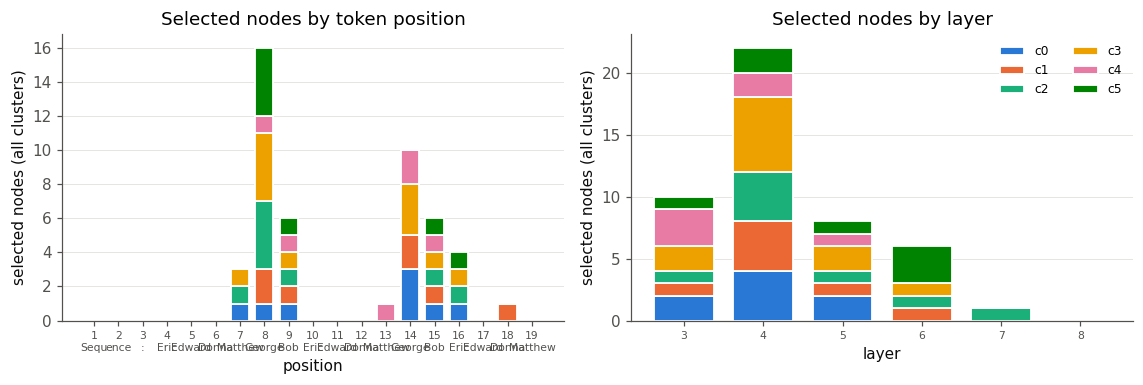

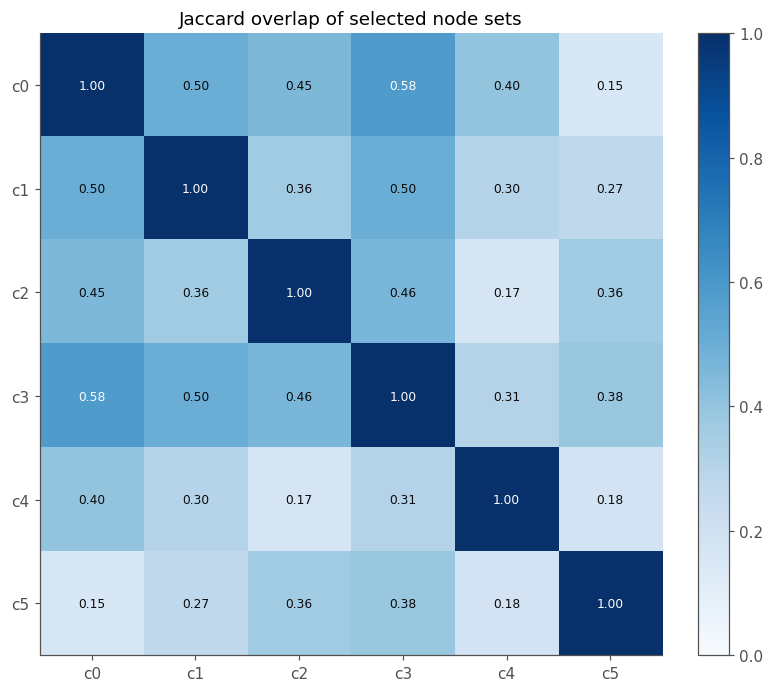

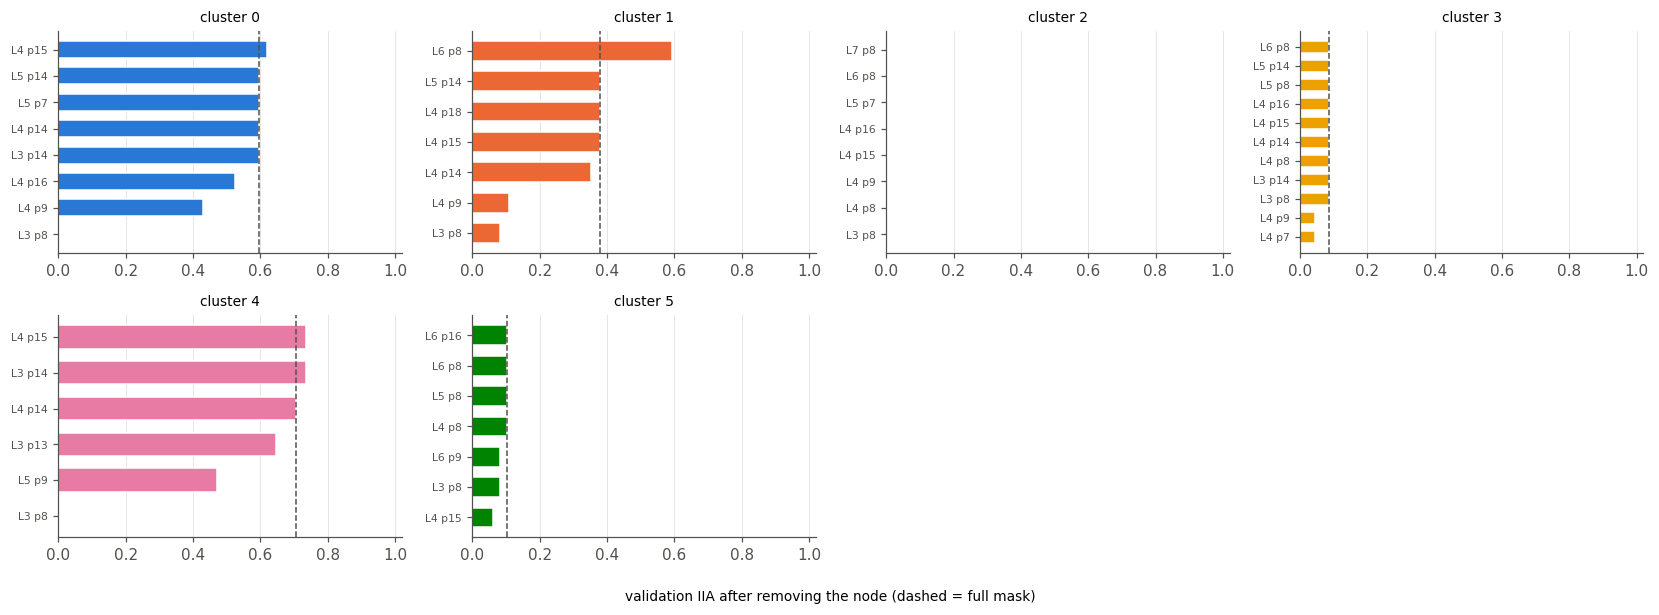

In [12]:
# =================== 7.1a  DCD grouping plots ===================
# (1) cluster composition by dataset variant (train + validation)
fig, ax = plt.subplots(figsize=(1.1 * chosen_k + 3, 3.6))
rows_all = train_records + val_records
bottom = np.zeros(chosen_k)
var_colors = {v: CAT[i] for i, v in enumerate(variants)}
for v in variants:
    vals = np.array([sum(1 for r in rows_all if r["cluster"] == c and r["variant"] == v) for c in range(chosen_k)])
    ax.bar(range(chosen_k), vals, bottom=bottom, color=var_colors[v], label=v, edgecolor="white", linewidth=1.5, width=0.7)
    bottom += vals
ax.set_xticks(range(chosen_k)); ax.set_xticklabels([f"c{c}" for c in range(chosen_k)])
ax.set_ylabel("examples (train + validation)"); ax.set_title("DCD cluster composition by dataset variant")
ax.legend(frameon=False, title="variant"); ax.grid(axis="x", visible=False)
savefig("01_cluster_composition")

# (2) gap statistic curve
fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.errorbar(gap_table["k"], gap_table["gap"], yerr=gap_table["s_k"], color=CAT[0], marker="o", capsize=3, lw=2, ms=6)
ax.axvline(chosen_k, color=GREY, ls="--", lw=1); ax.text(chosen_k, ax.get_ylim()[0], f" K={chosen_k}", color=INK2, va="bottom")
ax.set_xlabel("number of clusters K"); ax.set_ylabel("gap statistic"); ax.set_title("Gap statistic (one-SE rule)")
savefig("02_gap_statistic")

# (3) PCA scatter coloured by cluster, marker by variant
fig, ax = plt.subplots(figsize=(5.6, 4.4))
markers = {v: m for v, m in zip(variants, ["o", "s", "^", "D"])}
for c in range(chosen_k):
    for v in variants:
        idx = [i for i, r in enumerate(train_records) if r["cluster"] == c and r["variant"] == v]
        if idx:
            ax.scatter(train_reduced[idx, 0], train_reduced[idx, 1], s=22, marker=markers[v], color=cluster_color(c),
                       edgecolor="white", linewidth=0.5, alpha=0.9, label=f"c{c} / {v}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Per-example EAP-IG binary vectors (train, PCA)")
ax.legend(frameon=False, fontsize=7, ncol=2, bbox_to_anchor=(1.01, 1), loc="upper left")
savefig("03_pca_clusters")

# =================== 7.1b  alignment-search results ===================
ok = [c for c in ok_clusters]
# (4) IIA per cluster: learned mask (train, val) vs baselines
fig, ax = plt.subplots(figsize=(1.3 * max(len(ok), 4) + 3, 3.8))
w = 0.16
series = [("train IIA (learned mask)", "train_iia", "#9ec5f2"), ("validation IIA (learned mask)", "val_iia", CAT[0]),
          ("val: random same-size mask", "val_random_mask_iia", CAT[3]), ("val: all candidate nodes", "val_full_patch_iia", "#b9b8b2"),
          ("val: no patch", "val_no_patch_iia", "#e4e3df")]
x = np.arange(len(ok))
for j, (lab, key, col) in enumerate(series):
    vals = [search_results[c][key] for c in ok]
    ax.bar(x + (j - 2) * w, vals, w * 0.88, color=col, label=lab, edgecolor="white", linewidth=1)
ax.errorbar(x, [search_results[c]["val_random_mask_iia"] for c in ok],
            yerr=[search_results[c]["val_random_mask_iia_std"] for c in ok], fmt="none", ecolor=INK2, capsize=2, lw=1)
ax.set_xticks(x); ax.set_xticklabels([f"c{c}\n(k={search_results[c]['n_selected']})" for c in ok])
ax.set_ylim(0, 1.05); ax.set_ylabel("IIA"); ax.set_title(f"Interchange-intervention accuracy per DCD cluster  (layers {start_layer}-{end_layer}, token policy: {TOKEN_POLICY})")
ax.legend(frameon=False, fontsize=8, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2)); ax.grid(axis="x", visible=False)
savefig("04_iia_per_cluster")

# (5) optimisation curves
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for c in ok:
    h = pd.DataFrame(search_results[c]["history"])
    axes[0].plot(h["epoch"], h["ce"], color=cluster_color(c), lw=2, label=f"c{c}")
    axes[1].plot(h["epoch"], h["n_selected"], color=cluster_color(c), lw=2, label=f"c{c}")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy (hard mask)"); axes[0].set_title("Optimisation loss")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("selected nodes"); axes[1].set_title("Mask size during search")
axes[1].legend(frameon=False, ncol=2, fontsize=8)
savefig("05_optimisation_curves")

# (6) selected-node maps (layer x token position)
ncols = min(4, max(1, len(ok))); nrows = int(np.ceil(len(ok) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 2.7 * nrows + 0.6), squeeze=False)
cmap = ListedColormap(["#e4e3df", "#ffffff", CAT[0]])   # grey = outside token window, white = candidate, blue = selected
for ax in axes.ravel(): ax.axis("off")
positions_all = list(range(1, prompt_length))
for ax, c in zip(axes.ravel(), ok):
    ax.axis("on"); ax.grid(False)
    grid = np.zeros((len(search_layers), len(positions_all)))
    for li, l in enumerate(search_layers):
        for pi, p in enumerate(positions_all):
            grid[li, pi] = 1 if p in window_positions else 0
    for (l, p) in search_results[c]["selected_nodes"]:
        grid[search_layers.index(l), positions_all.index(p)] = 2
    ax.imshow(grid, cmap=cmap, vmin=0, vmax=2, aspect="auto", origin="lower")
    ax.set_xticks(range(len(positions_all))); ax.set_xticklabels(pos_tick_labels(positions_all), fontsize=6)
    ax.set_yticks(range(len(search_layers))); ax.set_yticklabels(search_layers, fontsize=7)
    ax.set_title(f"cluster {c}  (val IIA {search_results[c]['val_iia']:.2f})", fontsize=9)
    ax.set_xticks(np.arange(-.5, len(positions_all), 1), minor=True); ax.set_yticks(np.arange(-.5, len(search_layers), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1); ax.tick_params(which="minor", length=0)
fig.suptitle("Selected residual-stream nodes (blue); grey = excluded by the token window; tokens shown from one example prompt", y=1.0, fontsize=10)
fig.supxlabel("token position", fontsize=9); fig.supylabel("layer", fontsize=9)
savefig("06_selected_node_maps")

# (7) where are the selected nodes?  by position and by layer, stacked by cluster
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for ax, axis_name, domain in [(axes[0], "position", positions_all), (axes[1], "layer", search_layers)]:
    bottom = np.zeros(len(domain))
    for c in ok:
        cnt = np.array([sum(1 for (l, p) in search_results[c]["selected_nodes"] if (p if axis_name == "position" else l) == d)
                        for d in domain])
        ax.bar(range(len(domain)), cnt, bottom=bottom, color=cluster_color(c), edgecolor="white", linewidth=1.2, width=0.75, label=f"c{c}")
        bottom += cnt
    ax.set_xticks(range(len(domain)))
    ax.set_xticklabels(pos_tick_labels(domain) if axis_name == "position" else domain, fontsize=7)
    ax.set_xlabel(axis_name); ax.set_ylabel("selected nodes (all clusters)"); ax.grid(axis="x", visible=False)
axes[0].set_title("Selected nodes by token position"); axes[1].set_title("Selected nodes by layer")
axes[1].legend(frameon=False, ncol=2, fontsize=8)
savefig("07_selected_by_position_and_layer")

# (8) mask overlap between clusters (Jaccard of selected node sets)
sets = {c: set(search_results[c]["selected_nodes"]) for c in ok}
J = np.array([[len(sets[a] & sets[b]) / max(1, len(sets[a] | sets[b])) for b in ok] for a in ok])
fig, ax = plt.subplots(figsize=(0.7 * len(ok) + 3, 0.7 * len(ok) + 2.2))
im = ax.imshow(J, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(ok))); ax.set_xticklabels([f"c{c}" for c in ok]); ax.set_yticks(range(len(ok))); ax.set_yticklabels([f"c{c}" for c in ok])
for i in range(len(ok)):
    for j in range(len(ok)):
        ax.text(j, i, f"{J[i, j]:.2f}", ha="center", va="center", fontsize=8, color="white" if J[i, j] > 0.55 else INK)
ax.set_title("Jaccard overlap of selected node sets"); plt.colorbar(im, ax=ax, fraction=0.046)
savefig("08_mask_overlap")

# (9) leave-one-out necessity of each selected node (validation IIA after removing it)
loo_clusters = [c for c in ok if search_results[c]["loo"]]
if loo_clusters:
    ncols = min(4, len(loo_clusters)); nrows = int(np.ceil(len(loo_clusters) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.8 * ncols, 2.6 * nrows + 0.4), squeeze=False)
    for ax in axes.ravel(): ax.axis("off")
    for ax, c in zip(axes.ravel(), loo_clusters):
        ax.axis("on")
        items = sorted(search_results[c]["loo"], key=lambda t: t[1])
        ax.barh(range(len(items)), [v for _, v in items], color=cluster_color(c), height=0.65, edgecolor="white")
        ax.axvline(search_results[c]["val_iia"], color=INK2, ls="--", lw=1)
        ax.set_yticks(range(len(items))); ax.set_yticklabels([f"L{l} p{p}" for (l, p), _ in items], fontsize=7)
        ax.set_xlim(0, 1.02); ax.set_title(f"cluster {c}", fontsize=9); ax.grid(axis="y", visible=False)
    fig.supxlabel("validation IIA after removing the node (dashed = full mask)", fontsize=9)
    savefig("09_leave_one_out")


cluster 0: best single node IIA=0.643; best single position (all layers 3-8) IIA=0.643 at position 19
cluster 1: best single node IIA=0.757; best single position (all layers 3-8) IIA=0.757 at position 19
cluster 2: best single node IIA=1.000; best single position (all layers 3-8) IIA=1.000 at position 19
cluster 3: best single node IIA=0.826; best single position (all layers 3-8) IIA=0.826 at position 19
cluster 4: best single node IIA=0.618; best single position (all layers 3-8) IIA=0.618 at position 19
cluster 5: best single node IIA=0.510; best single position (all layers 3-8) IIA=0.510 at position 19


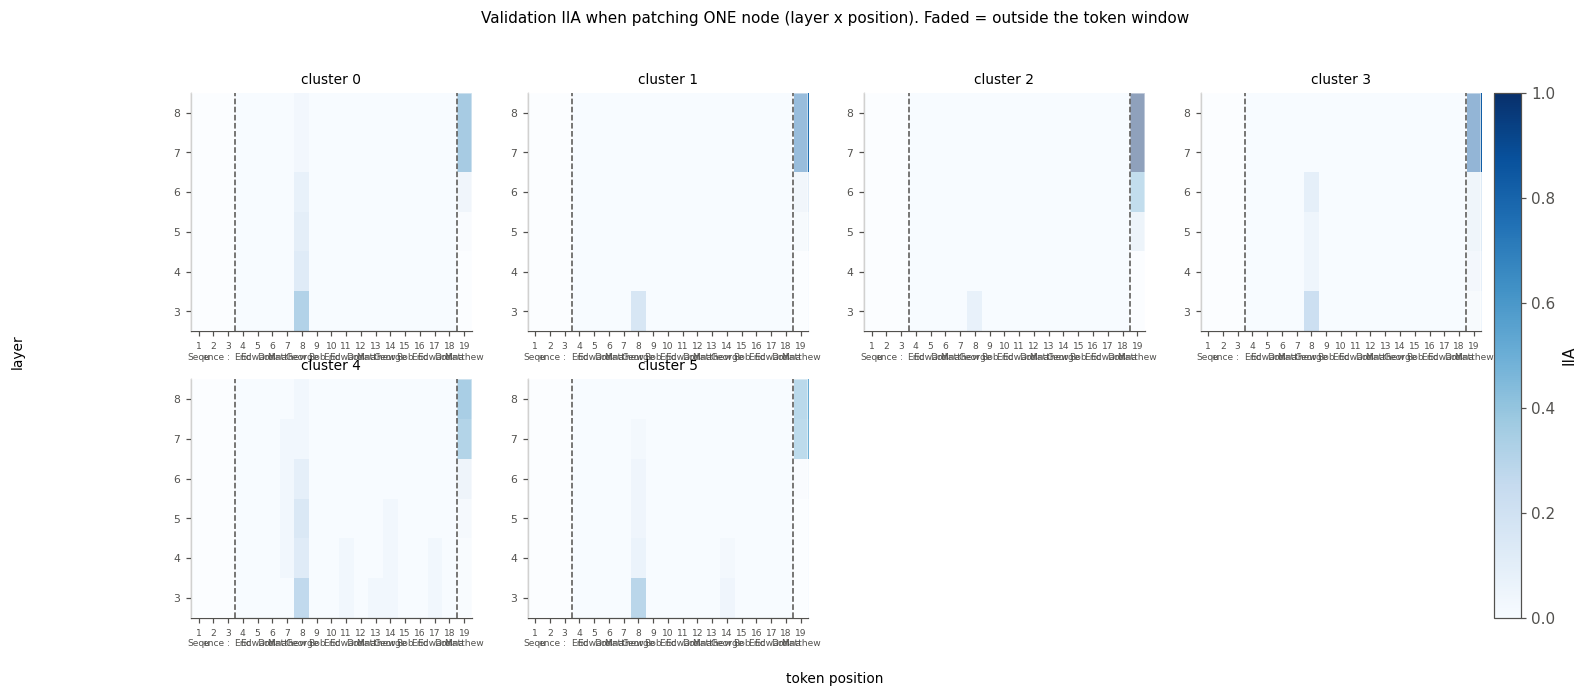

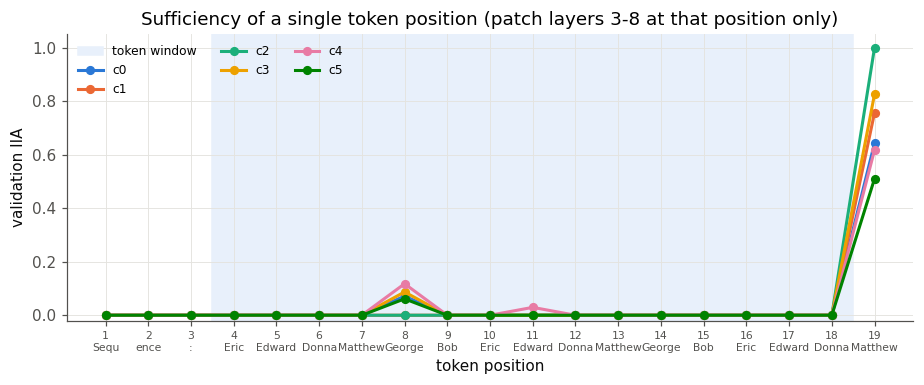

In [13]:
# =================== 7.2  single-node and single-position IIA (full layer x token grid) ===================
full_positions = list(range(1, prompt_length))
full_nodes = make_nodes(search_layers, full_positions)
single_node_iia, position_sufficiency = {}, {}
for c in ok_clusters:
    vp = group_val_pairs[c]; vg = target_ids_from_transfer_pairs(vp)
    prep = _prepare(model, vp, full_nodes, vg)
    grid = np.full((len(search_layers), len(full_positions)), np.nan)
    for i, (l, p) in enumerate(full_nodes):
        m = torch.zeros(len(full_nodes)); m[i] = 1
        grid[search_layers.index(l), full_positions.index(p)] = evaluate_iia(model, vp, full_nodes, vg, m, prepared=prep)["iia"]
    single_node_iia[c] = grid
    suff = []
    for p in full_positions:   # patch ALL search layers at this one position
        m = torch.tensor([1.0 if q == p else 0.0 for (_, q) in full_nodes])
        suff.append(evaluate_iia(model, vp, full_nodes, vg, m, prepared=prep)["iia"])
    position_sufficiency[c] = np.array(suff)
    print(f"cluster {c}: best single node IIA={np.nanmax(grid):.3f}; best single position (all layers {start_layer}-{end_layer}) "
          f"IIA={max(suff):.3f} at position {full_positions[int(np.argmax(suff))]}")

# heatmaps: single node (layer, position) IIA on validation pairs
ncols = min(4, max(1, len(ok_clusters))); nrows = int(np.ceil(len(ok_clusters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(3.9 * ncols, 2.7 * nrows + 0.8), squeeze=False)
for ax in axes.ravel(): ax.axis("off")
for ax, c in zip(axes.ravel(), ok_clusters):
    ax.axis("on"); ax.grid(False)
    im = ax.imshow(single_node_iia[c], cmap=SEQ, vmin=0, vmax=1, aspect="auto", origin="lower")
    lo, hi = full_positions.index(window_positions[0]) - 0.5, full_positions.index(window_positions[-1]) + 0.5
    ax.axvspan(-0.5, lo, color="white", alpha=0.55, zorder=3); ax.axvspan(hi, len(full_positions) - 0.5, color="white", alpha=0.55, zorder=3)
    ax.axvline(lo, color=INK2, lw=1, ls="--", zorder=4); ax.axvline(hi, color=INK2, lw=1, ls="--", zorder=4)
    ax.set_xticks(range(len(full_positions))); ax.set_xticklabels(pos_tick_labels(full_positions), fontsize=6)
    ax.set_yticks(range(len(search_layers))); ax.set_yticklabels(search_layers, fontsize=7)
    ax.set_title(f"cluster {c}", fontsize=9)
fig.suptitle("Validation IIA when patching ONE node (layer x position). Faded = outside the token window", y=1.0, fontsize=10)
fig.supxlabel("token position", fontsize=9); fig.supylabel("layer", fontsize=9)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=0.02, pad=0.01, label="IIA")
plt.savefig(FIG_DIR / "10_single_node_iia.png", dpi=160, bbox_inches="tight"); plt.show()

# line plot: IIA when patching all search layers at a single position
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.axvspan(window_positions[0] - 0.5, window_positions[-1] + 0.5, color="#e8f0fb", zorder=0, label="token window")
for c in ok_clusters:
    ax.plot(full_positions, position_sufficiency[c], marker="o", ms=5, lw=2, color=cluster_color(c), label=f"c{c}")
ax.set_xticks(full_positions); ax.set_xticklabels(pos_tick_labels(full_positions), fontsize=7)
ax.set_ylim(-0.02, 1.05); ax.set_ylabel("validation IIA"); ax.set_xlabel("token position")
ax.set_title(f"Sufficiency of a single token position (patch layers {start_layer}-{end_layer} at that position only)")
ax.legend(frameon=False, ncol=3, fontsize=8, loc="upper left")
savefig("11_position_sufficiency")


,val c0,val c1,val c2,val c3,val c4,val c5
mask c0,0.595,0.676,0.692,0.652,0.618,0.551
mask c1,0.357,0.378,0.615,0.174,0.471,0.367
mask c2,0.000,0.000,0.000,0.087,0.118,0.122
mask c3,0.167,0.054,0.077,0.087,0.235,0.102
mask c4,0.643,0.649,0.692,0.652,0.706,0.510
mask c5,0.119,0.000,0.000,0.043,0.147,0.102


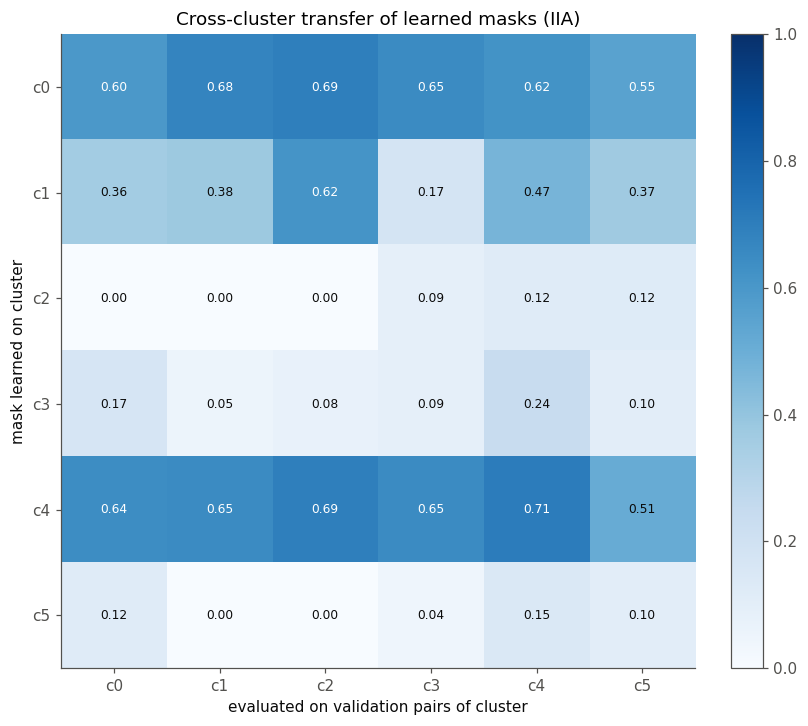

mean diagonal IIA=0.311 | mean off-diagonal IIA=0.320


In [14]:
# =================== 7.3  cross-cluster mask transfer ===================
# Mask learned on cluster i (rows) evaluated on cluster j's VALIDATION pairs (columns); same candidate nodes for all clusters.
val_preps = {}
for c in ok_clusters:
    vg = target_ids_from_transfer_pairs(group_val_pairs[c])
    val_preps[c] = (_prepare(model, group_val_pairs[c], nodes, vg), vg)
T = np.zeros((len(ok_clusters), len(ok_clusters)))
for a, i in enumerate(ok_clusters):
    for b, j in enumerate(ok_clusters):
        prep, vg = val_preps[j]
        T[a, b] = evaluate_iia(model, group_val_pairs[j], nodes, vg, search_results[i]["mask_hard"], prepared=prep)["iia"]
transfer_table = pd.DataFrame(T, index=[f"mask c{c}" for c in ok_clusters], columns=[f"val c{c}" for c in ok_clusters])
display(transfer_table.round(3))

fig, ax = plt.subplots(figsize=(0.75 * len(ok_clusters) + 3, 0.75 * len(ok_clusters) + 2.2))
im = ax.imshow(T, cmap=SEQ, vmin=0, vmax=1); ax.grid(False)
ax.set_xticks(range(len(ok_clusters))); ax.set_xticklabels([f"c{c}" for c in ok_clusters])
ax.set_yticks(range(len(ok_clusters))); ax.set_yticklabels([f"c{c}" for c in ok_clusters])
for a in range(len(ok_clusters)):
    for b in range(len(ok_clusters)):
        ax.text(b, a, f"{T[a, b]:.2f}", ha="center", va="center", fontsize=8, color="white" if T[a, b] > 0.55 else INK)
ax.set_xlabel("evaluated on validation pairs of cluster"); ax.set_ylabel("mask learned on cluster")
ax.set_title("Cross-cluster transfer of learned masks (IIA)"); plt.colorbar(im, ax=ax, fraction=0.046)
savefig("12_cross_cluster_transfer")
off = T[~np.eye(len(ok_clusters), dtype=bool)] if len(ok_clusters) > 1 else np.array([np.nan])
print(f"mean diagonal IIA={np.mean(np.diag(T)):.3f} | mean off-diagonal IIA={np.nanmean(off):.3f}")



### policy 'diff_span': positions 4..18 (15), nodes=90
  policy=diff_span    cluster=0  k=12  val IIA=0.167  positions=[7, 8, 9, 14, 15, 16]
  policy=diff_span    cluster=1  k=10  val IIA=0.027  positions=[8, 9, 14, 15]
  policy=diff_span    cluster=2  k=12  val IIA=0.077  positions=[8, 9, 14, 15, 16]
  policy=diff_span    cluster=3  k=12  val IIA=0.087  positions=[7, 8, 9, 14, 15, 16]
  policy=diff_span    cluster=4  k=11  val IIA=0.206  positions=[8, 9, 14, 15]
  policy=diff_span    cluster=5  k=12  val IIA=0.102  positions=[8, 9, 14, 15, 16]

### policy 'all': positions 1..19 (19), nodes=114
  policy=all          cluster=0  k=13  val IIA=1.000  positions=[8, 9, 14, 19]
  policy=all          cluster=1  k=11  val IIA=1.000  positions=[8, 14, 19]
  policy=all          cluster=2  k=13  val IIA=1.000  positions=[8, 14, 19]
  policy=all          cluster=3  k=12  val IIA=1.000  positions=[6, 8, 14, 19]
  policy=all          cluster=4  k=15  val IIA=1.000  positions=[8, 9, 14, 19]
  policy

,policy,cluster,n_window_positions,n_selected,train_iia,val_iia,val_random_iia,share_at_final_position,max_selected_position,selected_positions
0,diff_span,0,15,12,0.145161,0.166667,0.142857,0.000000,16,"[7, 8, 9, 14, 15, 16]"
1,diff_span,1,15,10,0.093220,0.027027,0.081081,0.000000,15,"[8, 9, 14, 15]"
2,diff_span,2,15,12,0.088889,0.076923,0.015385,0.000000,16,"[8, 9, 14, 15, 16]"
3,diff_span,3,15,12,0.103448,0.086957,0.034783,0.000000,16,"[7, 8, 9, 14, 15, 16]"
4,diff_span,4,15,11,0.295455,0.205882,0.167647,0.000000,15,"[8, 9, 14, 15]"
5,diff_span,5,15,12,0.169118,0.102041,0.183673,0.000000,16,"[8, 9, 14, 15, 16]"
6,all,0,19,13,1.000000,1.000000,0.176190,0.230769,19,"[8, 9, 14, 19]"
7,all,1,19,11,1.000000,1.000000,0.402703,0.272727,19,"[8, 14, 19]"
8,all,2,19,13,1.000000,1.000000,0.392308,0.230769,19,"[8, 14, 19]"
9,all,3,19,12,1.000000,1.000000,0.191304,0.250000,19,"[6, 8, 14, 19]"


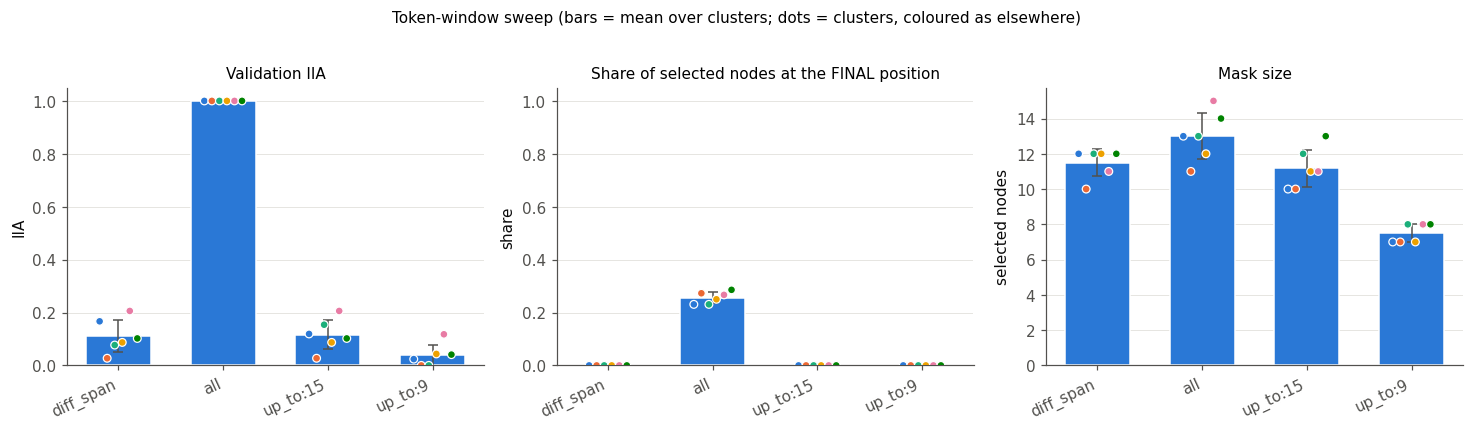

In [15]:
# =================== 7.4  token-window sweep ===================
# Re-runs the search under different token policies (same layers, same optimiser) to measure how much IIA and which nodes
# depend on late tokens / the readout position.  Cost ~ (#policies x #clusters x SWEEP_EPOCHS) optimiser epochs.
RUN_WINDOW_SWEEP = True
SWEEP_POLICIES = ["diff_span", "all", "up_to:15", "up_to:9"]          # first entry should be the main policy
SWEEP_EPOCHS = 150                           # reduced for cost; raise towards SEARCH_EPOCHS for the final paper figures
SWEEP_CLUSTERS = None                        # None = all ok clusters, or e.g. [0, 3]

sweep_rows, sweep_results = [], {}
if RUN_WINDOW_SWEEP:
    sweep_cl = ok_clusters if SWEEP_CLUSTERS is None else [c for c in SWEEP_CLUSTERS if c in ok_clusters]
    for pol in SWEEP_POLICIES:
        pos = build_token_window(diff_profile, pol, MIN_DIFF_FRAC, ALLOW_FINAL_POSITION)
        nodes_pol = make_nodes(search_layers, pos)
        print(f"\n### policy {pol!r}: positions {pos[0]}..{pos[-1]} ({len(pos)}), nodes={len(nodes_pol)}")
        for c in sweep_cl:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes_pol, epochs=SWEEP_EPOCHS,
                                 verbose=False, do_loo=False, n_random=10)
            sweep_results[(pol, c)] = r
            if r["status"] != "ok":
                continue
            sel_pos = [p for _, p in r["selected_nodes"]]
            sweep_rows.append({"policy": pol, "cluster": c, "n_window_positions": len(pos), "n_selected": r["n_selected"],
                               "train_iia": r["train_iia"], "val_iia": r["val_iia"], "val_random_iia": r["val_random_mask_iia"],
                               "share_at_final_position": (np.mean([p == final_position for p in sel_pos]) if sel_pos else np.nan),
                               "max_selected_position": (max(sel_pos) if sel_pos else np.nan),
                               "selected_positions": sorted(set(sel_pos))})
            print(f"  policy={pol:<12} cluster={c}  k={r['n_selected']:2d}  val IIA={r['val_iia']:.3f}  "
                  f"positions={sorted(set(sel_pos))}")
    sweep_df = pd.DataFrame(sweep_rows)
    display(sweep_df)

    if len(sweep_df):
        pols = [p for p in SWEEP_POLICIES if p in set(sweep_df["policy"])]
        fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.8))
        for ax, (col, title, ylab) in zip(axes, [("val_iia", "Validation IIA", "IIA"),
                                                  ("share_at_final_position", "Share of selected nodes at the FINAL position", "share"),
                                                  ("n_selected", "Mask size", "selected nodes")]):
            means, errs = [], []
            for k, pol in enumerate(pols):
                sub = sweep_df[sweep_df.policy == pol]
                means.append(sub[col].mean()); errs.append(sub[col].std(ddof=0) if len(sub) > 1 else 0)
            ax.bar(range(len(pols)), means, yerr=errs, color=CAT[0], width=0.62, capsize=3, edgecolor="white", error_kw=dict(ecolor=INK2, lw=1))
            for k, pol in enumerate(pols):   # one dot per cluster
                sub = sweep_df[sweep_df.policy == pol]
                ax.scatter(np.full(len(sub), k) + np.linspace(-0.18, 0.18, max(len(sub), 1))[:len(sub)], sub[col],
                           s=26, c=[cluster_color(c) for c in sub.cluster], edgecolor="white", linewidth=0.8, zorder=3)
            ax.set_xticks(range(len(pols))); ax.set_xticklabels(pols, rotation=25, ha="right")
            ax.set_title(title, fontsize=10); ax.set_ylabel(ylab); ax.grid(axis="x", visible=False)
            if col != "n_selected": ax.set_ylim(0, 1.05)
        fig.suptitle("Token-window sweep (bars = mean over clusters; dots = clusters, coloured as elsewhere)", y=1.02, fontsize=10)
        savefig("13_token_window_sweep")


In [16]:
# =================== 7.5  (optional) seed stability and sparsity sweep ===================
RUN_SEED_STABILITY = False
STABILITY_SEEDS = [1, 2]
RUN_LAMBDA_SWEEP = False
LAMBDA_VALUES = [0.03, 0.1, 0.3, 1.0]
LAMBDA_CLUSTERS = ok_clusters[:2]
OPT_EPOCHS = 150

stab_rows = []
if RUN_SEED_STABILITY:
    for c in ok_clusters:
        base_set = set(search_results[c]["selected_nodes"])
        for s in STABILITY_SEEDS:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes, epochs=SEARCH_EPOCHS,
                                 seed_offset=s, verbose=False, do_loo=False, n_random=5)
            sel = set(r["selected_nodes"])
            stab_rows.append({"cluster": c, "seed_offset": s, "n_selected": len(sel), "val_iia": r["val_iia"],
                              "jaccard_vs_main": len(sel & base_set) / max(1, len(sel | base_set))})
    stab_df = pd.DataFrame(stab_rows); display(stab_df)
    fig, ax = plt.subplots(figsize=(6, 3.4))
    for c in ok_clusters:
        sub = stab_df[stab_df.cluster == c]
        ax.scatter(sub["jaccard_vs_main"], sub["val_iia"], s=50, color=cluster_color(c), edgecolor="white", label=f"c{c}")
    ax.set_xlabel("Jaccard of selected nodes vs. main run"); ax.set_ylabel("validation IIA"); ax.set_xlim(0, 1.02); ax.set_ylim(0, 1.05)
    ax.set_title("Seed stability of the learned mask"); ax.legend(frameon=False, ncol=2, fontsize=8)
    savefig("14_seed_stability")

lam_rows = []
if RUN_LAMBDA_SWEEP:
    for c in LAMBDA_CLUSTERS:
        for lam in LAMBDA_VALUES:
            r = run_group_search(c, group_train_pairs[c], group_val_pairs[c], nodes, epochs=OPT_EPOCHS, lambda_=lam,
                                 verbose=False, do_loo=False, n_random=5)
            lam_rows.append({"cluster": c, "lambda": lam, "n_selected": r["n_selected"], "val_iia": r["val_iia"]})
    lam_df = pd.DataFrame(lam_rows); display(lam_df)
    fig, ax = plt.subplots(figsize=(5.6, 3.6))
    for c in LAMBDA_CLUSTERS:
        sub = lam_df[lam_df.cluster == c].sort_values("n_selected")
        ax.plot(sub["n_selected"], sub["val_iia"], marker="o", lw=2, color=cluster_color(c), label=f"c{c}")
    ax.set_xlabel("selected nodes (varied via lambda)"); ax.set_ylabel("validation IIA"); ax.set_ylim(0, 1.05)
    ax.set_title("Sparsity vs. IIA"); ax.legend(frameon=False)
    savefig("15_lambda_sweep")


Test EAP-IG:   0%|          | 0/200 [00:00<?, ?it/s]

,cluster,test_pairs,test_iia,test_random_iia,val_iia,train_iia
0,0,42,0.547619,0.039286,0.595238,0.717742
1,1,41,0.268293,0.054878,0.378378,0.305085
2,2,11,0.000000,0.127273,0.000000,0.044444
3,3,32,0.187500,0.059375,0.086957,0.091954
4,4,26,0.769231,0.038462,0.705882,0.602273
5,5,47,0.063830,0.091489,0.102041,0.132353


Test pools are small (200 test examples spread over K clusters): treat per-cluster test IIA as indicative only.


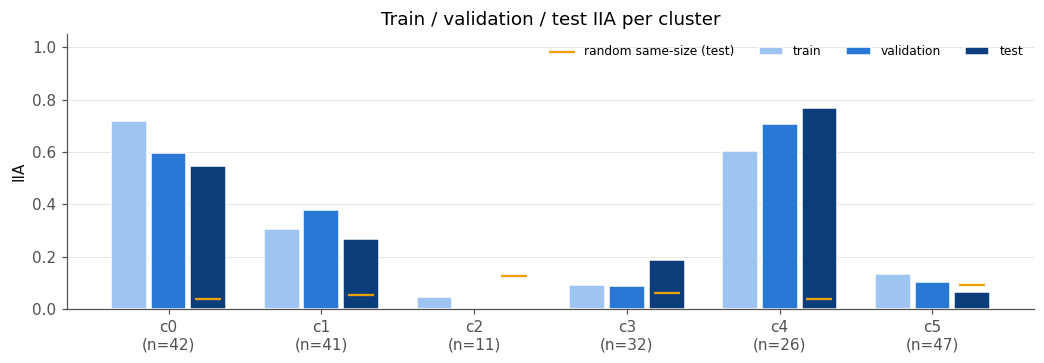

In [17]:
# =================== 7.6  confirmatory evaluation on the untouched test split ===================
# Test examples were never used for clustering, optimisation or validation. Here they get EAP-IG vectors, are assigned to the
# TRAINING-fitted PCA/K-means clusters, and each cluster's learned mask is evaluated once on within-cluster test pairs.
RUN_TEST_EVAL = True
test_table = pd.DataFrame()
if RUN_TEST_EVAL:
    test_records = add_clean_correctness_flags(model, test_records)
    test_vecs = [compute_one_eap_ig_vector(r, ig_steps=IG_STEPS) for r in tqdm(test_records, desc="Test EAP-IG")]
    test_bin = np.stack([binarize_attribution_mass(v, gamma=GAMMA) for v in test_vecs]).astype(np.float32)
    test_labels = clusterer.predict(pca.transform(test_bin))
    for r, lab in zip(test_records, test_labels): r["cluster"] = int(lab)
    rows = []
    for c in ok_clusters:
        tp = build_group_transfer_pairs([r for r in test_records if r["cluster"] == c], rng_seed=SEED + 200 + 10 * c)
        if len(tp) < MIN_VAL_PAIRS:
            rows.append({"cluster": c, "test_pairs": len(tp), "test_iia": np.nan, "test_random_iia": np.nan,
                         "val_iia": search_results[c]["val_iia"]}); continue
        tg = target_ids_from_transfer_pairs(tp); prep = _prepare(model, tp, nodes, tg)
        mask = search_results[c]["mask_hard"]
        t_iia = evaluate_iia(model, tp, nodes, tg, mask, prepared=prep)["iia"]
        rnd = random_baseline_samples(tp, tg, nodes, int(mask.sum()), RANDOM_BASELINE_TRIALS, prep) if mask.sum() > 0 else [np.nan]
        rows.append({"cluster": c, "test_pairs": len(tp), "test_iia": t_iia, "test_random_iia": float(np.mean(rnd)),
                     "val_iia": search_results[c]["val_iia"], "train_iia": search_results[c]["train_iia"]})
    test_table = pd.DataFrame(rows); display(test_table)
    print("Test pools are small (200 test examples spread over K clusters): treat per-cluster test IIA as indicative only.")
    t = test_table.dropna(subset=["test_iia"])
    if len(t):
        fig, ax = plt.subplots(figsize=(1.1 * len(t) + 3, 3.4)); x = np.arange(len(t)); w = 0.26
        ax.bar(x - w, t["train_iia"], w * 0.9, color="#9ec5f2", label="train", edgecolor="white")
        ax.bar(x, t["val_iia"], w * 0.9, color=CAT[0], label="validation", edgecolor="white")
        ax.bar(x + w, t["test_iia"], w * 0.9, color="#0b3d7a", label="test", edgecolor="white")
        ax.scatter(x + w, t["test_random_iia"], marker="_", s=300, color=CAT[3], zorder=4, label="random same-size (test)")
        ax.set_xticks(x); ax.set_xticklabels([f"c{c}\n(n={n})" for c, n in zip(t.cluster, t.test_pairs)])
        ax.set_ylim(0, 1.05); ax.set_ylabel("IIA"); ax.set_title("Train / validation / test IIA per cluster"); ax.legend(frameon=False, ncol=4, fontsize=8)
        ax.grid(axis="x", visible=False); savefig("16_train_val_test_iia")


In [18]:
# =================== 7.7  save everything needed to write up the results ===================
def _jsonable(o):
    if isinstance(o, (np.floating, np.integer)): return o.item()
    if isinstance(o, np.ndarray): return o.tolist()
    if isinstance(o, torch.Tensor): return o.tolist()
    if isinstance(o, (set, tuple)): return list(o)
    return str(o)

summary = {
    "config": {"model": model.cfg.model_name, "search_layers": search_layers, "token_policy": TOKEN_POLICY,
               "token_window": window_positions, "final_position": final_position, "min_diff_frac": MIN_DIFF_FRAC,
               "epochs": SEARCH_EPOCHS, "lambda": SEARCH_LAMBDA, "K": SEARCH_K, "lr": SEARCH_LR, "seed": SEED,
               "chosen_k": chosen_k, "n_candidate_nodes": len(nodes)},
    "clusters": {int(c): {k: v for k, v in r.items() if k not in ("mask_hard", "alpha", "history", "nodes", "loo")}
                 for c, r in search_results.items()},
}
with open(OUT_DIR / "summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=_jsonable)
group_results_table.to_csv(OUT_DIR / "group_results.csv", index=False)
selected_table.to_csv(OUT_DIR / "selected_nodes.csv", index=False)
gap_table.to_csv(OUT_DIR / "gap_statistic.csv", index=False)
cluster_summary.to_csv(OUT_DIR / "cluster_summary.csv", index=False)
pd.DataFrame({"position": range(prompt_length), "token": example_tokens, "diff_fraction": diff_profile,
              "in_window": [p in window_positions for p in range(prompt_length)]}).to_csv(OUT_DIR / "token_window.csv", index=False)
try: transfer_table.to_csv(OUT_DIR / "cross_cluster_transfer.csv")
except NameError: pass
try: sweep_df.to_csv(OUT_DIR / "token_window_sweep.csv", index=False)
except NameError: pass
try: test_table.to_csv(OUT_DIR / "test_results.csv", index=False)
except NameError: pass
np.savez(OUT_DIR / "single_node_iia.npz", layers=np.array(search_layers), positions=np.array(full_positions),
         **{f"cluster_{c}": single_node_iia[c] for c in single_node_iia},
         **{f"position_sufficiency_{c}": position_sufficiency[c] for c in position_sufficiency})
torch.save({c: {"mask_hard": r["mask_hard"], "alpha": r["alpha"], "nodes": r["nodes"]}
            for c, r in search_results.items() if r["status"] == "ok"}, OUT_DIR / "masks.pt")
print("Saved to", OUT_DIR.resolve()); print(sorted(p.name for p in OUT_DIR.iterdir()))
print("Figures:", sorted(p.name for p in FIG_DIR.iterdir()))


Saved to /content/results
['attr_matrix.npy', 'cluster_assignments.csv', 'cluster_summary.csv', 'cross_cluster_transfer.csv', 'figures', 'gap_statistic.csv', 'group_results.csv', 'masks.pt', 'selected_nodes.csv', 'single_node_iia.npz', 'summary.json', 'test_results.csv', 'token_window.csv', 'token_window_sweep.csv']
Figures: ['01_cluster_composition.png', '02_gap_statistic.png', '03_pca_clusters.png', '04_iia_per_cluster.png', '05_optimisation_curves.png', '06_selected_node_maps.png', '07_selected_by_position_and_layer.png', '08_mask_overlap.png', '09_leave_one_out.png', '10_single_node_iia.png', '11_position_sufficiency.png', '12_cross_cluster_transfer.png', '13_token_window_sweep.png', '16_train_val_test_iia.png']


In [20]:
import shutil

# Compress the results directory into a zip archive
shutil.make_archive('results', 'zip', 'results')
print("Archive 'results.zip' created successfully!")

Archive 'results.zip' created successfully!


## 8. Readout and interpretation

- **DCD cluster** is assigned from each example's per-example edge-attribution pattern, not from the alignment mask.
- **Selected nodes** are residual-stream `hook_resid_post` locations restricted to the chosen layer range and the **token window**; the window excludes positions that cannot yet contain the varied information and the final (readout) position, so a high IIA can no longer be obtained by overwriting the answer at the last token.
- **Validation IIA** = fraction of within-cluster base prompts whose intervened next-token prediction equals the donor's target after patching the learned mask. Compare with the no-patch, all-candidate-node and size-matched random-mask baselines (and with the test IIA in 7.6).
- **Token-window sweep (7.4)** quantifies the effect of the restriction. If IIA under `all` is high mainly because of final-position nodes (see `share_at_final_position`), that is a readout shortcut and not evidence about where the information is represented.
- **Cross-cluster transfer (7.3)** and **mask overlap** show whether different DCD groups use different nodes; mind that groups that only recover the manual dataset variant are a sanity check and not evidence of finer mechanistic diversity.
- Caveats: residual-stream node masks and EAP-IG edge circuits are different objects; the donor prompt contains the donor answer token, so patching at the positions where that token sits can transfer the answer identity directly.


## References

- Rai, Geva & Yao, *Data-driven Circuit Discovery for Interpretability of Language Models*, [arXiv:2605.09129](https://arxiv.org/abs/2605.09129). The DCD-Cluster pipeline uses per-example EAP-IG edge attributions, 99% absolute-mass binarization, 20-D PCA, and gap-statistic K-means.
- [DCD implementation repository](https://github.com/Ziyu-Yao-NLP-Lab/data-driven-circuit-discovery).
- [EAP-IG implementation](https://github.com/hannamw/EAP-IG).

**Reproducibility note:** attribution and optimization outputs are generated when the notebook is executed. No cluster assignments, node lists, or IIA results are fabricated in this file.
- Carry-ones alignment search (this project's original notebook) for the optimiser, and its layer/token restriction logic (positions that cannot yet contain the varied information are never candidates; the final prompt position is excluded).
